---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*Preprocessing, pemodelan Naive Bayes (from scratch), cost-sensitive classification, optimasi TAN, dan submisi Kaggle untuk memprediksi pembatalan pesanan Ronaldo Hotel.*

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

*Ronaldo Hotel membutuhkan sistem yang mengestimasi pengunjung yang akan membatalkan pesanan, agar kapasitas kamar dapat dikelola dengan lebih akurat tanpa sumber daya sebesar deep learning. Notebook ini membangun jalur preprocessing dan model Naive Bayes dari nol, lalu membandingkannya dengan scikit-learn.*

## Aim

*Menentukan, dengan bukti validasi silang, setiap keputusan preprocessing yang cocok untuk Naive Bayes, yaitu cleaning, transformasi, seleksi fitur, dan reduksi dimensi. Keluarannya adalah satu pipeline yang hanya mempelajari statistik dari data latih, serta model yang dapat disimpan, dimuat, dan menghasilkan submisi Kaggle yang dapat direproduksi.*

## Metric

***Macro F1-score** adalah metrik resmi kompetisi, yaitu rata-rata F1 kelas batal dan kelas tidak batal. Memprediksi seluruh pesanan tidak batal menghasilkan akurasi 0,67 tetapi Macro F1 hanya 0,40.*

$$\text{Macro F1} = \frac{F_1^{(0)} + F_1^{(1)}}{2}$$

***ROC-AUC** dilaporkan untuk kualitas peringkat skor tanpa bergantung pada threshold, dan dipakai sebagai kriteria pemilihan fitur karena lebih halus dan kurang berderau daripada F1.*

## Dataset

*Data berasal dari kompetisi Kaggle Tugas Besar 2 IF3170: https://www.kaggle.com/competitions/T2-IF3170-2026-2027. Terdiri atas 27.373 baris latih berlabel dan 6.844 baris uji tanpa label.*

**Attributes**

1.  `num_adults`, `num_children`   : Jumlah tamu dewasa dan anak
2.  `weekend_nights`, `weekday_nights` : Jumlah malam akhir pekan dan hari kerja
3.  `meal_package`, `room_category`, `booking_channel` : Paket makan, kategori kamar, kanal pemesanan
4.  `needs_parking`, `is_returning_guest` : Kebutuhan parkir dan status tamu lama (0 atau 1)
5.  `days_before_arrival`          : Jarak hari antara pemesanan dan kedatangan
6.  `arrival_year`, `arrival_month`, `arrival_day` : Tanggal kedatangan
7.  `prior_cancellations`, `prior_completed_bookings` : Riwayat tamu
8.  `nightly_rate_idr`             : Tarif per malam dalam rupiah
9.  `special_requests`             : Jumlah permintaan khusus

**Target**
 `is_canceled` : Status pembatalan (0: Tidak batal, 1: Batal)

*Deskripsi di atas disimpulkan dari nama kolom dan perlu dicocokkan dengan halaman resmi kompetisi.*

## Approach

*Naive Bayes menghitung $P(c)\prod_j P(x_j \mid c)$. Karena itu keputusan preprocessing-nya berbeda dari SVM:*

| Aspek | Konsekuensi untuk Naive Bayes |
|---|---|
| Scaling | Secara matematis tidak mengubah hasil, kecuali lewat batas bawah variansi (`var_smoothing`) yang dihitung dari fitur berskala terbesar (diuji di bagian Data Preparation, Feature Scaling) |
| Kategorikal | Cukup tabel frekuensi dengan Laplace smoothing, tanpa one-hot |
| Numerik | Gaussian jika bentuknya cocok, atau didiskretisasi lalu diperlakukan sebagai kategori |
| Nilai kosong | Dapat dimarginalkan, yaitu fitur dilewati saat menghitung skor |
| Fitur berkorelasi | Merusak asumsi independensi, sehingga fitur yang bergantung digabung atau dibuang |

```
Cleaning (kosong, duplikat, outlier)
    |
Transformasi (encoding, diskretisasi, fitur gabungan, imbalance)
    |
Seleksi fitur (diagnostik ketergantungan, filter, wrapper)
    |
Reduksi dimensi (PCA) -> Pemodelan (NB, TAN) -> Artifact -> Submisi
```

*Setiap keputusan dinilai dengan Stratified 5-Fold. Preprocessing dipelajari ulang di dalam setiap fold, dan train serta test tidak pernah digabung.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook berjalan pada CPU. Dependensi ada pada `requirements.txt` di root repository. Model Naive Bayes (`nb.py`) hanya memakai NumPy. Pandas, matplotlib, dan scikit-learn dipakai untuk data, visualisasi, dan pembanding.

## Import Libraries

In [ ]:
import json
import os
import platform
import random
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.naive_bayes import CategoricalNB, GaussianNB

sys.path.insert(0, str(Path.cwd()))

from nb import NaiveBayes
from tan import TANNaiveBayes
from preprocessing import (COUNT_CAP, DATA_DIR, ID_COL, RAW_CATEGORICAL, RAW_NUMERIC, TARGET, Preprocessor, cross_validate, load_test, load_train, macro_f1, roc_auc, stratified_folds)
from selection import FoldCache, forward_selection

## Seed Everything

In [2]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Path, palet, dan parameter eksperimen dipusatkan di sini. Palet memakai ungu-biru untuk kelas batal dan biru langit untuk kelas tidak batal.

In [ ]:
class Settings:
    SEED       = 42
    OUTPUT_DIR = Path('output')
    FIG_DIR    = OUTPUT_DIR / 'figures'
    FOLDS      = 5
    CHECK_SEEDS = [42, 7, 2026, 99]

    POS_COLOR    = '#6c4fc4'   
    NEG_COLOR    = '#4a8fd0'   
    ACCENT_COLOR = '#a64ca6'  
    MID_COLOR    = '#e8e7e3'
    SURFACE      = '#fcfcfb'
    INK          = '#0b0b0b'
    MUTED        = '#52514e'

CFG = Settings()
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.facecolor': CFG.SURFACE, 'axes.facecolor': CFG.SURFACE,
    'savefig.facecolor': CFG.SURFACE, 'figure.dpi': 110,
    'axes.edgecolor': CFG.MUTED, 'axes.labelcolor': CFG.MUTED,
    'axes.titlecolor': CFG.INK, 'axes.titlesize': 11, 'axes.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': CFG.MID_COLOR, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'xtick.color': CFG.MUTED, 'ytick.color': CFG.MUTED,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.frameon': False,
    'legend.fontsize': 8, 'font.size': 9,
})
pd.set_option('display.max_columns', 50, 'display.width', 160)

DIVERGING = LinearSegmentedColormap.from_list(
    'blue_gray_violet', [CFG.NEG_COLOR, CFG.MID_COLOR, CFG.POS_COLOR]
)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    'violet_ramp', [CFG.SURFACE, CFG.POS_COLOR, '#2a1a63']
)

def save_fig(name: str):
    plt.tight_layout()
    plt.savefig(CFG.FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Load Dataset

Berkas dibaca sebagai dua objek terpisah dan tidak digabung di bagian mana pun. Duplikat identik pada train dibuang di bagian Data Preparation (Duplicates).

In [4]:
train_raw = load_train(drop_duplicates=False)
train = load_train()
test = load_test()
y = train[TARGET].to_numpy()

assert not set(train['id']) & set(test['id'])
print(f'train mentah {train_raw.shape}, train bersih {train.shape}, test {test.shape}')
print(f'rasio batal {y.mean():.4f}, baseline Macro F1 (semua tidak batal) '
      f'{macro_f1(y, np.zeros_like(y)):.4f}')

train mentah (27373, 19), train bersih (27309, 19), test (6844, 18)
rasio batal 0.3275, baseline Macro F1 (semua tidak batal) 0.4021


## Helper Evaluasi

`evaluate` menjalankan Stratified 5-Fold dengan preprocessing yang dipelajari ulang di setiap fold, lalu mengembalikan Macro F1 dan ROC-AUC. Model Naive Bayes yang dipakai adalah hasil implementasi from scratch.

In [ ]:
def evaluate(spec, label, seed=42, winsorize=True, **model_kwargs):
    r = cross_validate(spec, NaiveBayes, train, y, n_folds=CFG.FOLDS, seed=seed, winsorize=winsorize,
                       model_kwargs=model_kwargs)
    return {'konfigurasi': label, 'macro_f1': r['macro_f1'], 'std': r['macro_f1_std'],
            'f1_threshold_held_out': r['macro_f1_held_out_threshold'], 'roc_auc': r['roc_auc'],
            '_odds': r['odds']}

def table(rows, cols=('konfigurasi', 'macro_f1', 'std', 'f1_threshold_held_out', 'roc_auc')):
    return pd.DataFrame(rows)[list(cols)].round(4)

COUNTS = ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'special_requests']

def base_spec(lead='q10', rate='q10'):
    spec = {c: 'cat' for c in COUNTS + RAW_CATEGORICAL}
    spec['days_before_arrival'] = lead
    spec['nightly_rate_idr'] = rate
    return spec

## Helper Pipeline

Daftar kandidat fitur (`build_pool`), fitur akhir hasil seleksi (`FINAL_FEATURES`), dan PCA from scratch dipusatkan di sini karena dipakai berulang di bagian berikutnya. `FINAL_FEATURES` ditulis tangan dan dicocokkan dengan hasil forward selection pada bagian Data Preparation (Feature Selection).

In [6]:
def cross(*parts):
    return ('cross', list(parts))

def build_pool():
    pool = {}
    for name in ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking',
                 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings',
                 'special_requests', 'arrival_year', 'arrival_month', 'arrival_day',
                 'meal_package', 'room_category', 'booking_channel']:
        pool[name] = 'cat'
    pool['lead_q5'] = cross(('days_before_arrival', 'q5'))
    pool['lead_q10'] = cross(('days_before_arrival', 'q10'))
    pool['lead_mdl'] = cross(('days_before_arrival', 'mdl'))
    pool['rate_q5'] = cross(('nightly_rate_idr', 'q5'))
    pool['rate_q10'] = cross(('nightly_rate_idr', 'q10'))
    pool['rate_mdl'] = cross(('nightly_rate_idr', 'mdl'))
    pool['days_before_arrival'] = 'gauss'
    pool['nightly_rate_idr'] = 'gauss'
    period = (('arrival_year', 'cat'), ('arrival_month', 'cat'))
    pool['x_period'] = cross(*period)
    pool['x_lead5_period'] = cross(('days_before_arrival', 'q5'), *period)
    pool['x_lead4_period'] = cross(('days_before_arrival', 'q4'), *period)
    pool['x_period_channel'] = cross(*period, ('booking_channel', 'cat'))
    pool['x_sr_channel'] = cross(('special_requests', 'cat'), ('booking_channel', 'cat'))
    pool['x_history'] = cross(('is_returning_guest', 'cat'), ('prior_completed_bookings', 'cat'),
                              ('prior_cancellations', 'cat'))
    pool['x_channel_lead5'] = cross(('booking_channel', 'cat'), ('days_before_arrival', 'q5'))
    pool['x_channel_rate5'] = cross(('booking_channel', 'cat'), ('nightly_rate_idr', 'q5'))
    pool['x_meal_channel'] = cross(('meal_package', 'cat'), ('booking_channel', 'cat'))
    pool['x_sr_lead5'] = cross(('special_requests', 'cat'), ('days_before_arrival', 'q5'))
    pool['x_adults_children'] = cross(('num_adults', 'cat'), ('num_children', 'cat'))
    pool['x_nights'] = cross(('weekend_nights', 'cat'), ('weekday_nights', 'cat'))
    pool['x_lead5_rate5'] = cross(('days_before_arrival', 'q5'), ('nightly_rate_idr', 'q5'))
    pool['x_room_meal'] = cross(('room_category', 'cat'), ('meal_package', 'cat'))
    pool['x_sr_rate5'] = cross(('special_requests', 'cat'), ('nightly_rate_idr', 'q5'))
    pool['x_lead5_parking'] = cross(('days_before_arrival', 'q5'), ('needs_parking', 'cat'))
    pool['x_channel_lead3'] = cross(('booking_channel', 'cat'), ('days_before_arrival', 'q3'))
    return pool

FINAL_FEATURES = ['x_lead5_period', 'x_sr_channel', 'rate_mdl', 'weekend_nights', 'needs_parking',
                  'room_category', 'arrival_day', 'prior_completed_bookings']

def final_spec():
    pool = build_pool()
    return {name: pool[name] for name in FINAL_FEATURES}

def pca_fit(X, n_components=None):
    mean = X.mean(axis=0)
    scale = X.std(axis=0)
    scale[scale == 0] = 1.0
    Z = (X - mean) / scale
    _, singular, vt = np.linalg.svd(Z, full_matrices=False)
    variance = singular ** 2 / (len(Z) - 1)
    ratio = variance / variance.sum()
    k = n_components or len(ratio)
    return mean, scale, vt[:k], ratio

def pca_transform(X, mean, scale, components):
    return ((X - mean) / scale) @ components.T

---

# Data Understanding <a name="3"></a>

---

## Describe Data

Ukuran data, tipe atribut, dan ringkasan statistik atribut numerik.

In [7]:
print(f'Train: {train.shape}  Test: {test.shape}')
overview = pd.DataFrame({'tipe': train.dtypes.astype(str), 'nilai unik': train.nunique(),
                         '% kosong': (train.isna().mean() * 100).round(2)})
display(overview)
display(train[RAW_NUMERIC].describe().T.round(2))

Train: (27309, 19)  Test: (6844, 18)


,tipe,nilai unik,% kosong
id,str,27309,0.00
num_adults,float64,5,2.96
num_children,float64,6,11.11
weekend_nights,int64,8,0.00
weekday_nights,int64,18,0.00
meal_package,str,4,6.44
needs_parking,float64,2,3.96
room_category,str,7,3.67
days_before_arrival,float64,407,4.10
arrival_year,int64,2,0.00


,count,mean,std,min,25%,50%,75%,max
num_adults,26500.0,1.85,0.52,0.0,2.0,2.0,2.0,4.0
num_children,24274.0,0.12,0.43,0.0,0.0,0.0,0.0,10.0
weekend_nights,27309.0,0.82,0.88,0.0,0.0,1.0,2.0,7.0
weekday_nights,27309.0,2.21,1.42,0.0,1.0,2.0,3.0,17.0
needs_parking,26227.0,0.03,0.17,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26189.0,85.26,85.88,0.0,17.0,58.0,126.0,448.0
is_returning_guest,27309.0,0.03,0.16,0.0,0.0,0.0,0.0,1.0
prior_cancellations,27309.0,0.02,0.36,0.0,0.0,0.0,0.0,13.0
prior_completed_bookings,27309.0,0.15,1.70,0.0,0.0,0.0,0.0,58.0
nightly_rate_idr,25317.0,1717449.93,587593.00,0.0,1338000.0,1644000.0,2020000.0,9165000.0


## Explore Data

Distribusi target, sebaran lead time per kelas, dan tingkat batal per kanal pemesanan.

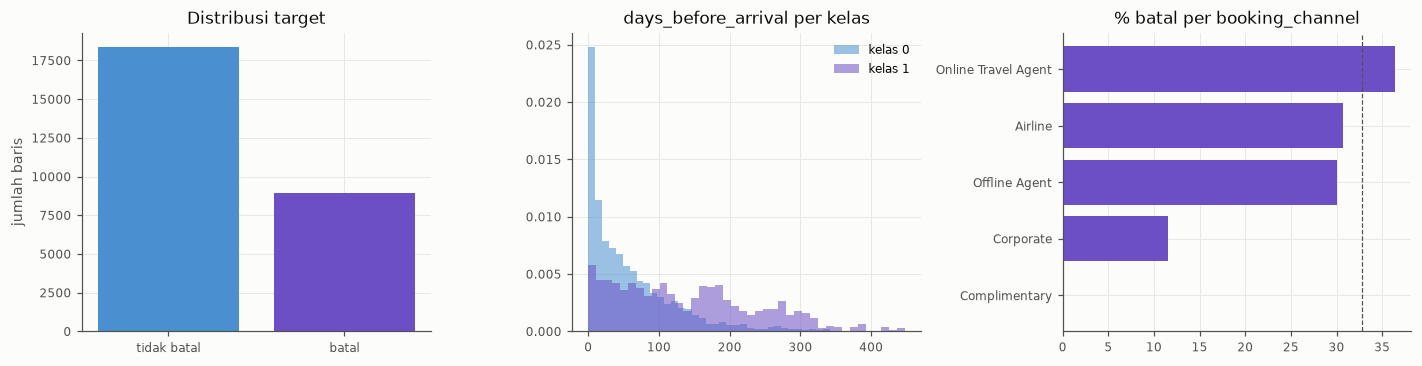

rasio batal 0.3275, perbandingan kelas 2.05 : 1


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
counts = pd.Series(y).value_counts().sort_index()
axes[0].bar(['tidak batal', 'batal'], counts.values, color=[CFG.NEG_COLOR, CFG.POS_COLOR])
axes[0].set_title('Distribusi target'); axes[0].set_ylabel('jumlah baris')
for cls, color in ((0, CFG.NEG_COLOR), (1, CFG.POS_COLOR)):
    axes[1].hist(train.loc[y == cls, 'days_before_arrival'].dropna(), bins=40, alpha=0.55, density=True,
                 color=color, label=f'kelas {cls}')
axes[1].set_title('days_before_arrival per kelas'); axes[1].legend()
rate = train.groupby('booking_channel')[TARGET].mean().sort_values() * 100
axes[2].barh(rate.index, rate.values, color=CFG.POS_COLOR)
axes[2].axvline(y.mean() * 100, color=CFG.MUTED, lw=0.8, ls='--')
axes[2].set_title('% batal per booking_channel')
save_fig('nb_understanding')
print(f'rasio batal {y.mean():.4f}, perbandingan kelas {counts[0] / counts[1]:.2f} : 1')

In [9]:
feature_cols = [c for c in train.columns if c not in ('id', TARGET)]
quality = pd.DataFrame([
    ('kolom dengan nilai kosong', f'{int(train[feature_cols].isna().any().sum())} dari {len(feature_cols)}'),
    ('baris lengkap', f'{train[feature_cols].notna().all(axis=1).mean() * 100:.1f}%'),
    ('baris duplikat identik pada train mentah', int(train_raw.duplicated(subset=feature_cols + [TARGET]).sum())),
    ('nilai negatif pada atribut numerik', int((train[RAW_NUMERIC] < 0).sum().sum())),
    ('arrival_month di luar 1..12', int((~train.arrival_month.dropna().between(1, 12)).sum())),
    ('arrival_day di luar 1..31', int((~train.arrival_day.dropna().between(1, 31)).sum())),
    ('id train yang juga ada di test', len(set(train['id']) & set(test['id']))),
], columns=['pemeriksaan', 'hasil'])
display(quality)

,pemeriksaan,hasil
0,kolom dengan nilai kosong,8 dari 17
1,baris lengkap,60.9%
2,baris duplikat identik pada train mentah,64
3,nilai negatif pada atribut numerik,0
4,arrival_month di luar 1..12,0
5,arrival_day di luar 1..31,0
6,id train yang juga ada di test,0


#### Insights

> Train berisi 27.309 baris dan test 6.844 baris, dengan 17 fitur ditambah target. Delapan dari 17 kolom memiliki nilai kosong dan hanya 60,9% baris yang lengkap. Kelas batal 32,75% (perbandingan 2,05 : 1), sehingga akurasi saja menyesatkan dan Macro F1 dipakai sebagai metrik.

> Tidak ada nilai negatif, bulan atau hari di luar rentang, maupun `id` yang sama antara train dan test. Ada 64 baris duplikat identik pada train mentah. Penanganan nilai kosong dan duplikat diputuskan di bagian Data Preparation.

---

# Training and Validation Split <a name="4"></a>

---

Pembagian dilakukan **berstrata** menurut target. Sebanyak 10% baris `train.csv` disisihkan sebagai `val_set` (seed 2026), dan 90% sisanya menjadi `train_set`. `test.csv` tidak ikut dibagi dan hanya dipakai untuk submisi Kaggle.

`val_set` tidak dipakai untuk memilih fitur, alpha, maupun threshold. Ia hanya dipakai pada estimasi hold-out di bagian Modeling and Validation, dengan seleksi fitur yang diulang dari awal hanya pada `train_set`. Keputusan di bagian Data Preparation diambil dengan Stratified 5-Fold atas seluruh `train`, dan preprocessing dipelajari ulang di dalam setiap fold.

In [10]:
split_folds = stratified_folds(y, 10, 2026)
train_idx, val_idx = split_folds[0]
train_set = train.iloc[train_idx].reset_index(drop=True)
val_set = train.iloc[val_idx].reset_index(drop=True)
y_train, y_val = y[train_idx], y[val_idx]

assert not set(train_set['id']) & set(val_set['id'])
display(pd.DataFrame({'baris': [len(train_set), len(val_set), len(test)],
                      'rasio batal': [y_train.mean(), y_val.mean(), np.nan]},
                     index=['train_set', 'val_set', 'test']).round(4))

,baris,rasio batal
train_set,24577,0.3275
val_set,2732,0.3276
test,6844,NaN


#### Insights

> `train_set` berisi 24.577 baris dan `val_set` 2.732 baris. Rasio batal hampir sama (0,3275 dan 0,3276), sehingga pembagian berstrata menjaga proporsi kelas dan hasil pada `val_set` dapat dibandingkan dengan hasil pada data latih.

---

# Data Preparation <a name="5"></a>

---

Setiap proses di bawah dipakai hanya jika data memintanya, dan blok *Insights* di bawahnya mencatat alasan keputusan. Semua statistik (batas diskretisasi, daftar kategori, batas winsorize) dipelajari dari bagian latih, lalu dipakai untuk mengubah bagian lain.

## Data Cleaning

### Missing Values

Persentase kosong dibandingkan antara train dan test, dan dihubungkan dengan target.

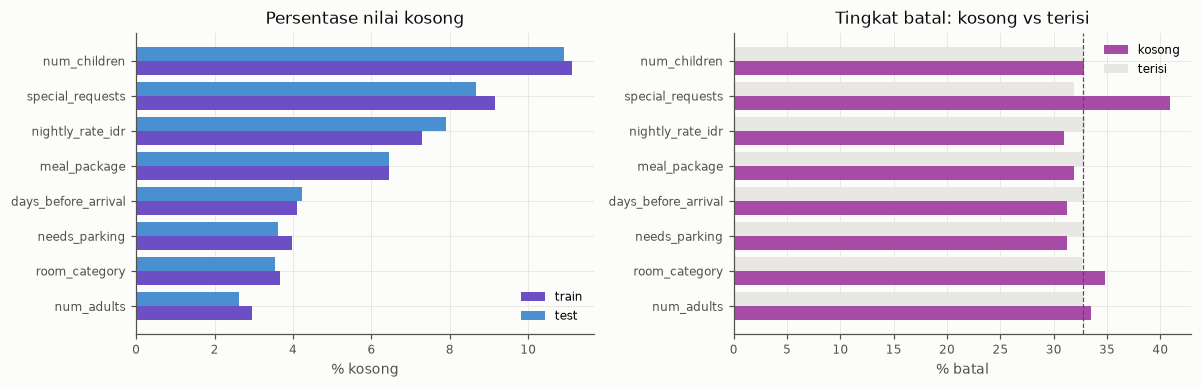

kolom dengan kekosongan berkaitan target (Bonferroni): ['special_requests']
baris lengkap: 60.9%


In [11]:
features = [c for c in train.columns if c not in ('id', TARGET)]
miss = pd.DataFrame({'train': train[features].isna().mean() * 100,
                     'test': test[features].isna().mean() * 100})
miss = miss[(miss > 0).any(axis=1)].sort_values('train')
rate_missing = {c: train.loc[train[c].isna(), TARGET].mean() * 100 for c in miss.index}
rate_present = {c: train.loc[train[c].notna(), TARGET].mean() * 100 for c in miss.index}
p_values = {c: stats.chi2_contingency(pd.crosstab(train[c].isna(), train[TARGET]))[1] for c in miss.index}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
idx = np.arange(len(miss))
axes[0].barh(idx - 0.2, miss['train'], 0.4, color=CFG.POS_COLOR, label='train')
axes[0].barh(idx + 0.2, miss['test'], 0.4, color=CFG.NEG_COLOR, label='test')
axes[0].set_yticks(idx); axes[0].set_yticklabels(miss.index)
axes[0].set_xlabel('% kosong'); axes[0].set_title('Persentase nilai kosong'); axes[0].legend()
axes[1].barh(idx - 0.2, [rate_missing[c] for c in miss.index], 0.4, color=CFG.ACCENT_COLOR, label='kosong')
axes[1].barh(idx + 0.2, [rate_present[c] for c in miss.index], 0.4, color=CFG.MID_COLOR, label='terisi')
axes[1].axvline(y.mean() * 100, color=CFG.MUTED, lw=0.8, ls='--')
axes[1].set_yticks(idx); axes[1].set_yticklabels(miss.index)
axes[1].set_xlabel('% batal'); axes[1].set_title('Tingkat batal: kosong vs terisi'); axes[1].legend()
save_fig('nb_missing')
alpha = 0.05 / len(p_values)
print('kolom dengan kekosongan berkaitan target (Bonferroni):',
      [c for c, p in p_values.items() if p < alpha])
print(f'baris lengkap: {train[features].notna().all(axis=1).mean() * 100:.1f}%')

Naive Bayes dapat menangani nilai kosong tanpa mengisinya: fitur yang kosong dilewati dalam perkalian likelihood (**marginalisasi**), dan hasilnya tepat secara matematis. Karena itu tidak ada nilai yang diisi dan tidak ada baris yang dibuang. Tabel berikut menunjukkan porsi baris yang dilewati pada tiap fitur akhir.

In [12]:
prep_final = Preprocessor(final_spec()).fit(train, y)
X_final = prep_final.transform(train)
skipped = pd.Series(np.isnan(X_final).mean(axis=0) * 100, index=prep_final.feature_names_).round(2)
display(skipped.rename('% baris dilewati').to_frame())
print(f'baris dengan setidaknya satu fitur dilewati: {np.isnan(X_final).any(axis=1).mean() * 100:.1f}%')

,% baris dilewati
x_lead5_period,4.10
x_sr_channel,9.15
rate_mdl,7.29
weekend_nights,0.00
needs_parking,3.96
room_category,3.67
arrival_day,0.00
prior_completed_bookings,0.00


baris dengan setidaknya satu fitur dilewati: 25.2%


#### Insights

> Delapan kolom memiliki nilai kosong dan hanya 60,9% baris yang lengkap, sehingga menghapus baris akan membuang sekitar 39% data dan tidak mungkin dilakukan pada test. Dari delapan kolom itu, hanya `special_requests` yang kekosongannya berkaitan dengan target setelah koreksi Bonferroni.

> Model tidak mengisi nilai apa pun. Pada fitur akhir, porsi baris yang dilewati (dimarginalkan) adalah 9,15% untuk `x_sr_channel`, 7,29% untuk `rate_mdl`, 4,10% untuk `x_lead5_period`, 3,96% untuk `needs_parking`, dan 3,67% untuk `room_category`. Sebanyak 25,2% baris memiliki setidaknya satu fitur yang dilewati, tetapi tidak ada baris yang kehilangan seluruh fiturnya. Fitur gabungan dilewati jika salah satu komponennya kosong, sehingga `x_sr_channel` kehilangan semua baris dengan `special_requests` kosong.

### Duplicates

Duplikat identik, termasuk labelnya, dibuang dari train. Baris test tidak pernah dihapus.

In [13]:
dup_cols = features + [TARGET]
n_dup = train_raw.duplicated(subset=dup_cols).sum()
conflict = (train_raw.duplicated(subset=features, keep=False).sum()
            - train_raw.duplicated(subset=dup_cols, keep=False).sum())
print(f'baris duplikat identik: {n_dup} ({n_dup / len(train_raw) * 100:.2f}%)')
print(f'baris dengan fitur sama tetapi label berbeda: {conflict}')
print(f'baris test yang fiturnya muncul di train: {test[features].merge(train[features].drop_duplicates(), how="inner").shape[0]}')

baris duplikat identik: 64 (0.23%)
baris dengan fitur sama tetapi label berbeda: 4
baris test yang fiturnya muncul di train: 42


#### Insights

> Terdapat 64 baris duplikat identik (0,23%) yang dibuang. Empat baris lain memiliki fitur sama tetapi label berbeda dan dipertahankan karena itu derau yang nyata. Sebanyak 42 baris test memiliki fitur yang sama dengan baris train, tetapi baris test tidak dihapus karena tetap harus diprediksi.

### Outliers and Data Errors

Nilai yang tampak aneh diperiksa terhadap target sebelum diputuskan. Outlier mengganggu Gaussian karena mean dan variansi sangat sensitif, sehingga fitur Gaussian di-*winsorize* pada persentil 0,5 dan 99,5 yang dipelajari dari data latih.

,kondisi,baris,% batal
0,nightly_rate_idr = 0,408,0.74
1,num_adults = 0,106,30.19
2,weekend+weekday nights = 0,64,3.12
3,weekend+weekday nights >= 15,55,80.00
4,special_requests >= 3,563,0.00


C:\Users\atias\AppData\Local\Temp\ipykernel_11488\1697468814.py:21: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0, k].boxplot(values, vert=False, patch_artist=True, boxprops=dict(facecolor=CFG.POS_COLOR, alpha=0.5),
C:\Users\atias\AppData\Local\Temp\ipykernel_11488\1697468814.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, k].boxplot(clipped, vert=False, patch_artist=True, boxprops=dict(facecolor=CFG.NEG_COLOR, alpha=0.5),
C:\Users\atias\AppData\Local\Temp\ipykernel_11488\1697468814.py:21: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0, k].boxplot(values, vert=False, patch_artist=True, boxprops=dict(facecolor=CFG.POS_COLOR, alp

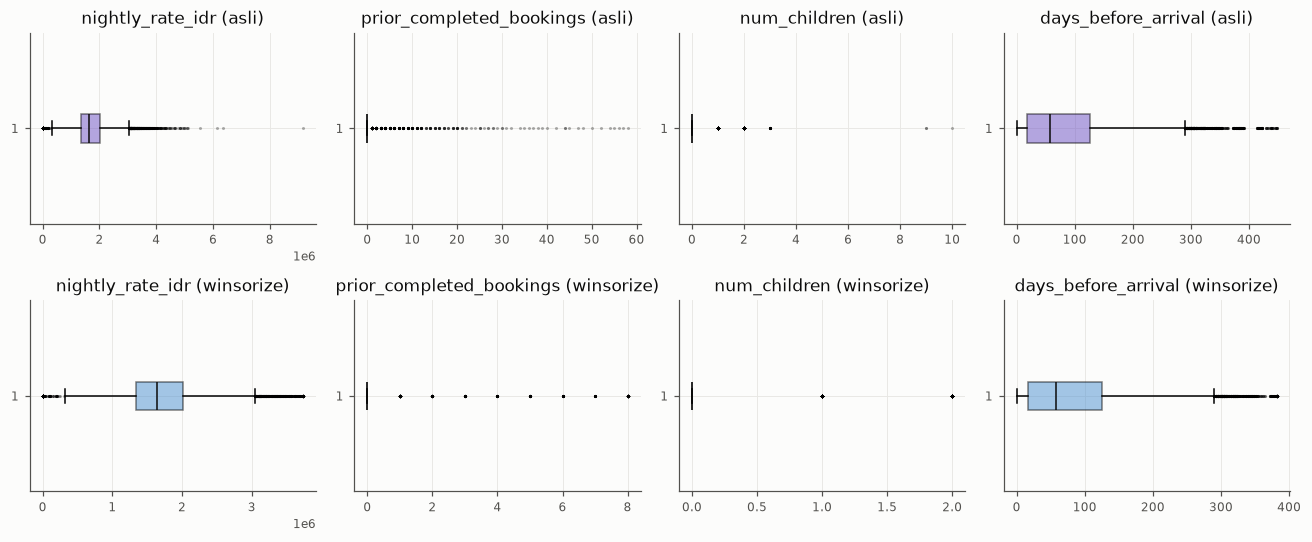

,nightly_rate_idr,prior_completed_bookings,num_children,days_before_arrival
p0.5,0.0,0.0,0.0,0.0
p99.5,3734100.0,8.0,2.0,382.0


In [14]:
checks = pd.DataFrame({
    'kondisi': ['nightly_rate_idr = 0', 'num_adults = 0', 'weekend+weekday nights = 0',
                'weekend+weekday nights >= 15', 'special_requests >= 3'],
    'baris': [(train.nightly_rate_idr == 0).sum(), (train.num_adults == 0).sum(),
              ((train.weekend_nights + train.weekday_nights) == 0).sum(),
              ((train.weekend_nights + train.weekday_nights) >= 15).sum(),
              (train.special_requests >= 3).sum()],
    '% batal': [train.loc[train.nightly_rate_idr == 0, TARGET].mean() * 100,
                train.loc[train.num_adults == 0, TARGET].mean() * 100,
                train.loc[(train.weekend_nights + train.weekday_nights) == 0, TARGET].mean() * 100,
                train.loc[(train.weekend_nights + train.weekday_nights) >= 15, TARGET].mean() * 100,
                train.loc[train.special_requests >= 3, TARGET].mean() * 100],
}).round(2)
display(checks)

cols = ['nightly_rate_idr', 'prior_completed_bookings', 'num_children', 'days_before_arrival']
bounds = {c: np.nanpercentile(train[c], (0.5, 99.5)) for c in cols}
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for k, c in enumerate(cols):
    values = train[c].dropna()
    axes[0, k].boxplot(values, vert=False, patch_artist=True, boxprops=dict(facecolor=CFG.POS_COLOR, alpha=0.5),
                       medianprops=dict(color=CFG.INK), flierprops=dict(marker='.', markersize=2, alpha=0.3))
    axes[0, k].set_title(f'{c} (asli)')
    clipped = values.clip(*bounds[c])
    axes[1, k].boxplot(clipped, vert=False, patch_artist=True, boxprops=dict(facecolor=CFG.NEG_COLOR, alpha=0.5),
                       medianprops=dict(color=CFG.INK), flierprops=dict(marker='.', markersize=2, alpha=0.3))
    axes[1, k].set_title(f'{c} (winsorize)')
save_fig('nb_outliers')
display(pd.DataFrame(bounds, index=['p0.5', 'p99.5']).round(1))

#### Insights

> Nilai yang tampak ganjil membawa informasi sehingga tidak dibuang. Tarif nol hanya batal 0,74% (408 baris), total malam nol batal 3,12% (64 baris), total malam minimal 15 batal 80,0% (55 baris), dan seluruh 563 baris dengan `special_requests` minimal 3 tidak batal. `num_adults = 0` (106 baris) batal 30,19%, hampir sama dengan rata-rata, sehingga dipertahankan sebagai nilai biasa.

> Hanya fitur Gaussian yang di-winsorize, pada persentil 0,5 dan 99,5 dari data latih: tarif dipangkas di 3,73 juta, `prior_completed_bookings` di 8, `num_children` di 2, dan `days_before_arrival` di 382. Fitur yang didiskretisasi atau dijadikan kategori tidak terpengaruh outlier karena nilai besar masuk ke interval atau kode teratas.

## Data Transformation

Transformasi menurunkan atribut dan mengubah nilai ke bentuk yang dibaca model.

### Encoding

Naive Bayes tidak membutuhkan one-hot: fitur kategorikal cukup diberi kode bilangan bulat dan likelihood-nya dihitung dari tabel frekuensi per kelas dengan Laplace smoothing. Kategori dengan kurang dari 30 baris digabung menjadi `lainnya`, dan nilai kosong dilewati saat menghitung likelihood.

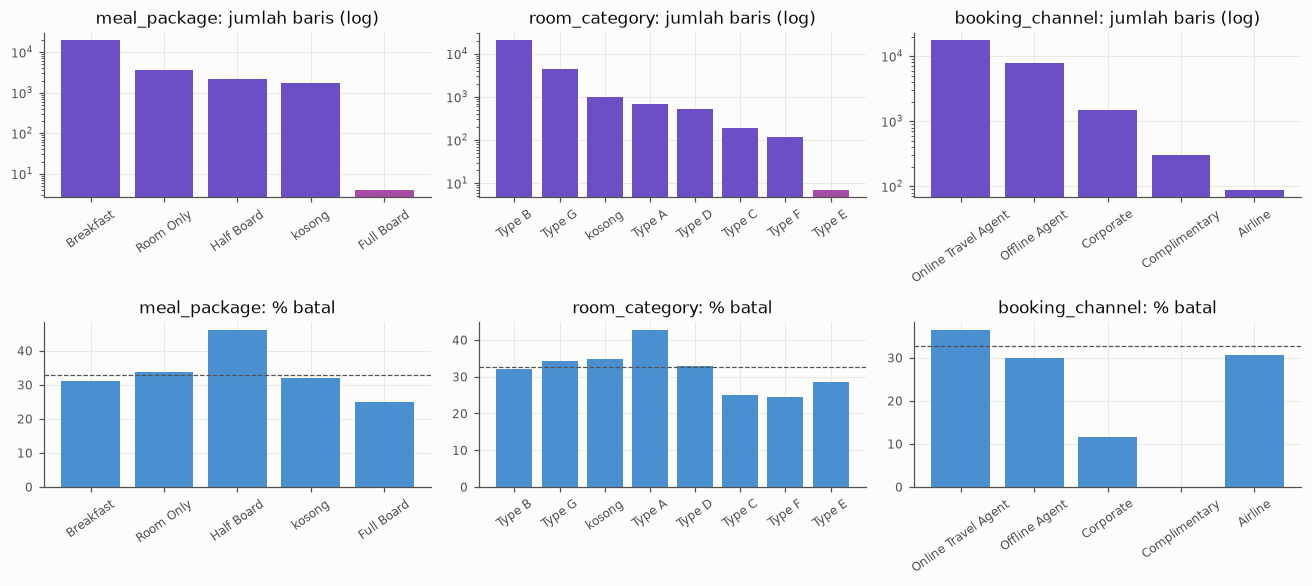

kategori yang digabung (kurang dari 30 baris, batang sorot):
  meal_package {'Full Board': 4}
  room_category {'Type E': 7}
  booking_channel {}


In [15]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.4))
for k, c in enumerate(RAW_CATEGORICAL):
    counts = train[c].fillna('kosong').value_counts()
    colors = [CFG.ACCENT_COLOR if v < 30 else CFG.POS_COLOR for v in counts.values]
    axes[0, k].bar(counts.index, counts.values, color=colors)
    axes[0, k].set_yscale('log'); axes[0, k].set_title(f'{c}: jumlah baris (log)')
    axes[0, k].tick_params(axis='x', rotation=35)
    rate = train.assign(_c=train[c].fillna('kosong')).groupby('_c')[TARGET].mean().reindex(counts.index) * 100
    axes[1, k].bar(rate.index, rate.values, color=CFG.NEG_COLOR)
    axes[1, k].axhline(y.mean() * 100, color=CFG.MUTED, lw=0.8, ls='--')
    axes[1, k].set_title(f'{c}: % batal'); axes[1, k].tick_params(axis='x', rotation=35)
save_fig('nb_categorical')
print('kategori yang digabung (kurang dari 30 baris, batang sorot):')
for c in RAW_CATEGORICAL:
    counts = train[c].fillna('kosong').value_counts()
    print(' ', c, counts[counts < 30].to_dict())

#### Insights

> `Full Board` (4 baris) dan `Type E` (7 baris) berada di bawah ambang 30 baris sehingga digabung menjadi `lainnya`. `booking_channel` tidak memerlukan penggabungan, kategori terkecilnya Airline masih 88 baris. Tingkat batal sangat berbeda antar kategori, terutama pada kanal pemesanan, sehingga likelihood per kategori membawa sinyal.

### Gaussian Fit: Apakah Fitur Numerik Cocok dengan Gaussian?

Gaussian NB mengasumsikan setiap fitur numerik berdistribusi normal di dalam kelasnya. Asumsi ini diuji pada dua fitur kontinu dengan menggambar distribusi per kelas bersama kurva normal terpasang, ditambah versi log. Statistik yang dilaporkan adalah skewness dan jarak Kolmogorov-Smirnov (KS) terhadap normal.

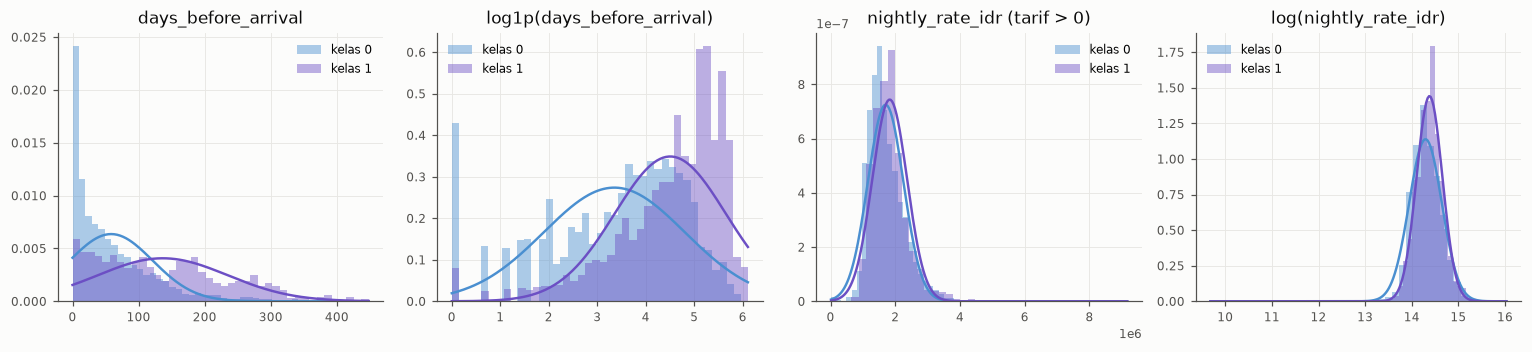

,fitur,skewness,KS kelas 0,KS kelas 1
0,days_before_arrival,1.308,0.176,0.082
1,log1p(days_before_arrival),-0.879,0.098,0.119
2,nightly_rate_idr (tarif > 0),1.179,0.084,0.086
3,log(nightly_rate_idr),-1.874,0.056,0.031


In [16]:
def gaussian_panel(ax, values, label_values, title):
    for cls, color in ((0, CFG.NEG_COLOR), (1, CFG.POS_COLOR)):
        v = values[label_values == cls]
        ax.hist(v, bins=40, density=True, alpha=0.45, color=color, label=f'kelas {cls}')
        grid = np.linspace(values.min(), values.max(), 200)
        ax.plot(grid, stats.norm.pdf(grid, v.mean(), v.std()), color=color, lw=1.6)
    ax.set_title(title); ax.legend()

ok = train[['days_before_arrival', 'nightly_rate_idr', TARGET]].dropna()
ok = ok[ok.nightly_rate_idr > 0]
variants = {'days_before_arrival': ok.days_before_arrival.to_numpy(float),
            'log1p(days_before_arrival)': np.log1p(ok.days_before_arrival.to_numpy(float)),
            'nightly_rate_idr (tarif > 0)': ok.nightly_rate_idr.to_numpy(float),
            'log(nightly_rate_idr)': np.log(ok.nightly_rate_idr.to_numpy(float))}
labels = ok[TARGET].to_numpy()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
rows = []
for ax, (name, v) in zip(axes, variants.items()):
    gaussian_panel(ax, v, labels, name)
    ks = [stats.kstest((v[labels == c] - v[labels == c].mean()) / v[labels == c].std(), 'norm').statistic for c in (0, 1)]
    rows.append({'fitur': name, 'skewness': stats.skew(v), 'KS kelas 0': ks[0], 'KS kelas 1': ks[1]})
save_fig('nb_gaussian_fit')
display(pd.DataFrame(rows).round(3))

#### Insights

> Tidak ada varian yang benar-benar normal. `days_before_arrival` miring ke kanan (skewness 1,308) dan KS terhadap normal 0,176 untuk kelas 0 dan 0,082 untuk kelas 1. Log1p mengoreksi terlalu jauh (skewness -0,879) dan KS kelas 1 justru naik menjadi 0,119. Tarif juga miring (1,179, KS sekitar 0,085), dan log tarif memiliki KS terkecil (0,056 dan 0,031) tetapi miring ke kiri (-1,874).

> Karena bentuknya berbeda antar kelas dan tidak mendekati normal, Gaussian bukan pilihan yang aman untuk dua fitur ini. Validasi silang pada bagian Discretization mengonfirmasinya untuk lead time: ROC-AUC Gaussian 0,8132, di bawah semua varian diskret (0,8158 sampai 0,8228).

### Discretization

Fitur numerik dapat didiskretisasi lalu diperlakukan sebagai kategori, sehingga bentuk hubungan apa pun (termasuk tidak monotonik) dapat ditangkap. Skema yang dibandingkan adalah Gaussian apa adanya, frekuensi sama (`q`), lebar sama (`w`), dan berbasis entropi dengan penghentian MDL (Fayyad dan Irani, 1993), yang memakai label sehingga dipelajari hanya dari fold latih.

,konfigurasi,macro_f1,std,f1_threshold_held_out,roc_auc
0,lead: gauss,0.7182,0.0097,0.7237,0.8132
1,rate: gauss,0.7264,0.0102,0.7316,0.8205
2,lead: q5,0.7269,0.0114,0.7309,0.8208
3,rate: q5,0.7269,0.0105,0.7356,0.8211
4,lead: q10,0.7253,0.0110,0.7324,0.8211
5,rate: q10,0.7253,0.0110,0.7324,0.8211
6,lead: q20,0.7274,0.0116,0.7362,0.8228
7,rate: q20,0.7269,0.0102,0.7341,0.8218
8,lead: w10,0.7242,0.0106,0.7227,0.8158
9,rate: w10,0.7263,0.0093,0.7340,0.8213


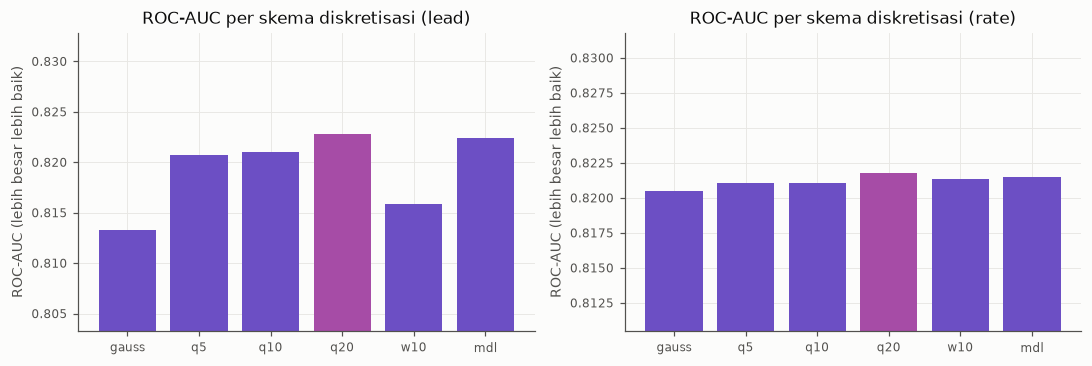

In [17]:
schemes = ['gauss', 'q5', 'q10', 'q20', 'w10', 'mdl']
rows = []
for scheme in schemes:
    for target_col, other in (('days_before_arrival', 'lead'), ('nightly_rate_idr', 'rate')):
        spec = base_spec()
        spec[target_col] = scheme
        r = evaluate(spec, f'{other}: {scheme}')
        r['fitur'], r['skema'] = other, scheme
        rows.append(r)
disc = pd.DataFrame(rows)
display(table(rows))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, feat in zip(axes, ('lead', 'rate')):
    part = disc[disc.fitur == feat]
    best = part.loc[part.roc_auc.idxmax(), 'skema']
    ax.bar(part.skema, part.roc_auc, color=[CFG.ACCENT_COLOR if s == best else CFG.POS_COLOR for s in part.skema])
    ax.set_ylim(part.roc_auc.min() - 0.01, part.roc_auc.max() + 0.01)
    ax.set_title(f'ROC-AUC per skema diskretisasi ({feat})'); ax.set_ylabel('ROC-AUC (lebih besar lebih baik)')
save_fig('nb_discretization')

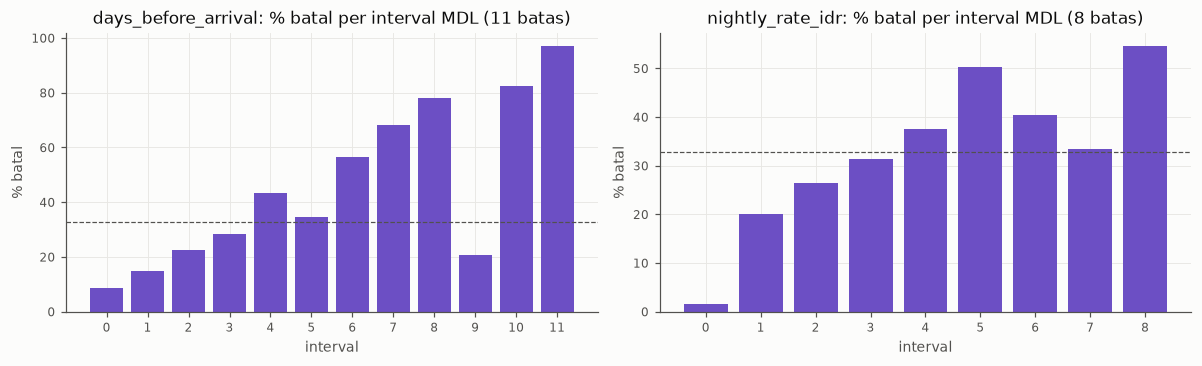

{'days_before_arrival': [5.5, 17.5, 61.5, 93.5, 112.5, 149.5, 158.5, 231.5, 327.5, 340.5, 374.5], 'nightly_rate_idr': [765500.0, 1187500.0, 1449500.0, 1601500.0, 1813500.0, 1954500.0, 2239500.0, 3505500.0]}


In [18]:
fit_prep = Preprocessor({'days_before_arrival': 'mdl', 'nightly_rate_idr': 'mdl'}).fit(train, y)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col in zip(axes, ('days_before_arrival', 'nightly_rate_idr')):
    cuts = fit_prep.cuts_[col]
    values = train[col]
    known = values.notna()
    codes = np.searchsorted(np.asarray(cuts), values[known].to_numpy(), side='right')
    rate = pd.Series(y[known.to_numpy()]).groupby(codes).mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=CFG.POS_COLOR)
    ax.axhline(y.mean() * 100, color=CFG.MUTED, lw=0.8, ls='--')
    ax.set_title(f'{col}: % batal per interval MDL ({len(cuts)} batas)')
    ax.set_xlabel('interval'); ax.set_ylabel('% batal')
save_fig('nb_mdl_bins')
print({c: [round(x, 1) for x in cuts] for c, cuts in fit_prep.cuts_.items()})

#### Insights

> Untuk `days_before_arrival`, diskretisasi mengalahkan Gaussian: ROC-AUC 0,8132 naik menjadi 0,8208 sampai 0,8228 dengan skema kuantil dan MDL (q20 0,8228, MDL 0,8224). Lebar sama (w10) paling lemah di antara skema diskret (0,8158), karena data lead time miring sehingga sebagian besar baris menumpuk di interval awal. Selisih antar skema kuantil dan MDL sangat kecil dan masih dalam derau.

> Untuk tarif, skema hampir tidak berpengaruh: ROC-AUC berkisar 0,8205 sampai 0,8218 untuk semua skema, termasuk Gaussian. Macro F1 antar skema juga berbeda kurang dari simpangan baku fold (sekitar 0,010). MDL dipakai untuk tarif karena tidak membutuhkan jumlah interval yang ditentukan sendiri, sedangkan lead time dipakai sebagai kuantil (q5) di dalam fitur gabungan agar sel gabungannya tidak terlalu jarang. Batas MDL lead time mencakup 149,5 dan 158,5 hari, dekat lompatan tingkat batal yang terlihat pada EDA, dan batas tarif 1,81 dan 1,95 juta mengapit tarif menengah-tinggi.

### Feature Scaling

Secara teori, standardisasi tidak mengubah prediksi Gaussian NB: mean dan variansi per kelas ikut berskala, sehingga log likelihood hanya bergeser oleh konstanta yang sama untuk kedua kelas. Namun implementasi memakai batas bawah variansi `var_smoothing` $\times$ variansi terbesar antar fitur (mengikuti scikit-learn), sehingga skala fitur terbesar ikut menentukan batas itu untuk semua fitur. Keduanya diuji langsung pada baris yang lengkap.

In [19]:
num = Preprocessor({c: 'gauss' for c in ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights',
                                         'prior_completed_bookings']}).fit(train, y)
X = num.transform(train)
complete = ~np.isnan(X).any(axis=1)
X, y_c = X[complete], y[complete]
Z = (X - X.mean(axis=0)) / X.std(axis=0)
rows = []
for smoothing in (1e-9, 0.0):
    raw = NaiveBayes(var_smoothing=smoothing).fit(X, y_c, num.feature_types_)
    std = NaiveBayes(var_smoothing=smoothing).fit(Z, y_c, num.feature_types_)
    rows.append({'var_smoothing': f'{smoothing:g}',
                 'selisih probabilitas maks': np.abs(raw.predict_proba(X) - std.predict_proba(Z)).max(),
                 'prediksi sama': bool((raw.predict(X) == std.predict(Z)).all()),
                 'Macro F1 mentah': macro_f1(y_c, raw.predict(X).astype(int)),
                 'Macro F1 standardisasi': macro_f1(y_c, std.predict(Z).astype(int))})
display(pd.DataFrame(rows).round(4))
print(f'baris lengkap yang dipakai: {complete.sum()} dari {len(complete)}')
print('simpangan baku fitur sebelum scaling:', X.std(axis=0).round(1))

,var_smoothing,selisih probabilitas maks,prediksi sama,Macro F1 mentah,Macro F1 standardisasi
0,1e-09,0.916,False,0.6899,0.3579
1,0,0.000,True,0.3579,0.3579


baris lengkap yang dipakai: 24276 dari 27309
simpangan baku fitur sebelum scaling: [8.420000e+01 5.761889e+05 1.400000e+00 7.000000e-01]


#### Insights

> Secara matematis standardisasi tidak mengubah hasil: dengan `var_smoothing = 0`, selisih probabilitas 0,000 dan semua prediksi sama. Dengan nilai bawaan `1e-9`, selisihnya mencapai 0,916 dan prediksi berubah (Macro F1 0,6899 pada data mentah dan 0,3579 setelah standardisasi), karena batas bawah variansi dihitung dari fitur dengan variansi terbesar (tarif, simpangan baku sekitar 576 ribu). Batas itu besar untuk fitur berskala kecil pada data mentah, tetapi jauh lebih kecil relatif terhadap variansinya setelah standardisasi.

> Kesetaraan pada `var_smoothing = 0` bersifat teoretis saja dan bukan konfigurasi yang layak: Macro F1 jatuh ke 0,3579, di bawah baseline semua-tidak-batal (0,4021), karena Gaussian yang sangat sempit (misalnya `prior_completed_bookings` pada kelas batal, variansi sekitar 0,009 pada seluruh data latih) memberi skor ekstrem. Jadi scaling bukan tahap wajib untuk Naive Bayes, tetapi batas bawah variansi tetap diperlukan dan membuat hasil bergantung pada skala pada blok Gaussian berskala campuran. Pipeline akhir seluruhnya kategorikal, sehingga masalah ini tidak berlaku. Pengujian memakai 24.276 dari 27.309 baris yang lengkap.

### Attribute Construction: Fitur Gabungan

Fitur baru dibuat hanya dengan menggabungkan kolom asli, tanpa menghitung kolom baru dari kolom lain. Karena asumsi independensi, dua fitur yang saling bergantung dihitung dua kali oleh Naive Bayes. Solusinya adalah **fitur gabungan** (cross), yaitu satu fitur kategorikal untuk nilai bersama dua atau tiga fitur, seperti pada semi-naive Bayes (Kononenko, 1991). Kombinasi dengan kurang dari 30 baris berbagi satu kode. Setiap kandidat ditambahkan satu per satu pada konfigurasi dasar dan dinilai dengan ROC-AUC.

,konfigurasi,macro_f1,std,f1_threshold_held_out,roc_auc
0,dasar,0.7253,0.0110,0.7324,0.8211
1,+ arrival_year,0.7386,0.0100,0.7426,0.8296
2,+ arrival_month,0.7332,0.0093,0.7356,0.8248
3,+ arrival_day,0.7280,0.0106,0.7340,0.8211
4,+ gabungan x_period,0.7466,0.0074,0.7474,0.8361
5,+ gabungan x_lead5_period,0.7411,0.0100,0.7468,0.8368
6,+ gabungan x_period_channel,0.7498,0.0079,0.7498,0.8402
7,+ gabungan x_sr_channel,0.7486,0.0063,0.7518,0.8328
8,+ gabungan x_history,0.7264,0.0107,0.7337,0.8210
9,+ gabungan x_channel_lead5,0.7338,0.0093,0.7351,0.8283


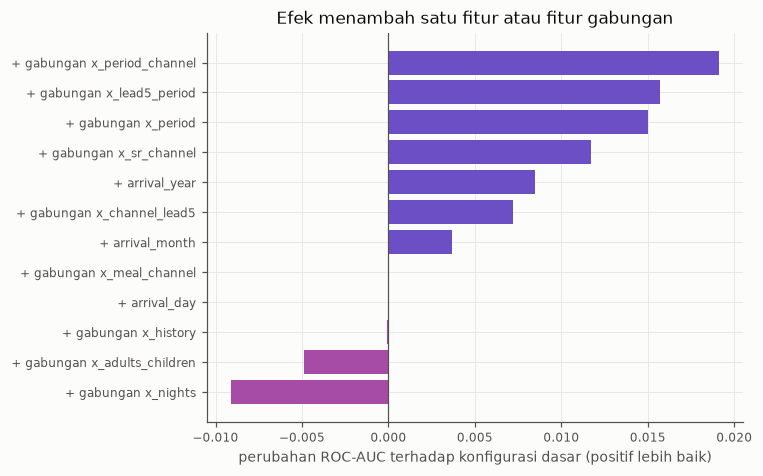

In [20]:
pool = build_pool()
def add(spec, *names):
    out = dict(spec)
    for n in names:
        out[n] = pool[n]
    return out

start = base_spec()
experiments = [('dasar', start)]
for name in ['arrival_year', 'arrival_month', 'arrival_day']:
    experiments.append((f'+ {name}', add(start, name)))
for name in ['x_period', 'x_lead5_period', 'x_period_channel', 'x_sr_channel', 'x_history',
             'x_channel_lead5', 'x_meal_channel', 'x_nights', 'x_adults_children']:
    experiments.append((f'+ gabungan {name}', add(start, name)))
rows = [evaluate(spec, label) for label, spec in experiments]
results = table(rows)
display(results)

delta = results.set_index('konfigurasi').roc_auc - results.roc_auc.iloc[0]
delta = delta.drop('dasar').sort_values()
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(delta.index, delta.values, color=[CFG.POS_COLOR if v > 0 else CFG.ACCENT_COLOR for v in delta.values])
ax.axvline(0, color=CFG.MUTED, lw=0.8)
ax.set_xlabel('perubahan ROC-AUC terhadap konfigurasi dasar (positif lebih baik)')
ax.set_title('Efek menambah satu fitur atau fitur gabungan')
save_fig('nb_engineering')

#### Insights

> Periode kedatangan paling berguna. Tahun saja menaikkan ROC-AUC dari 0,8211 menjadi 0,8296 dan bulan saja menjadi 0,8248, sedangkan gabungan keduanya (`x_period`) mencapai 0,8361 dan Macro F1 0,7466. Menggabungkan periode dengan kanal pemesanan (`x_period_channel`) memberi ROC-AUC tertinggi (0,8402), dan periode dengan lead time (`x_lead5_period`) 0,8368. Tanggal (`arrival_day`) sendirian tidak membantu (0,8211).

> `x_sr_channel` (permintaan khusus dan kanal) menaikkan ROC-AUC ke 0,8328 dan memberi Macro F1 dengan threshold held-out tertinggi (0,7518). `x_channel_lead5` memberi kenaikan sedang (0,8283). Fitur gabungan yang tidak bergantung hanya menambah sel yang jarang dan tidak membantu atau merugikan: `x_history` (0,8210) dan `x_meal_channel` (0,8211) tidak berubah, sedangkan `x_nights` (0,8120) dan `x_adults_children` (0,8162) justru menurunkan ROC-AUC.

### Class Balance

Rasio kelas sekitar 2 banding 1. Pada Naive Bayes, ketidakseimbangan masuk lewat prior $P(c)$, sehingga ada tiga cara menanganinya tanpa membuat data sintetis: prior apa adanya, prior disetarakan (50:50), atau menggeser threshold pada log odds. Ketiganya dibandingkan memakai pipeline akhir.

,konfigurasi,macro_f1,std,f1_threshold_held_out,roc_auc
0,prior dipelajari,0.7770,0.0051,0.7815,0.8636
1,prior disetarakan 50:50,0.7573,0.0035,0.7821,0.8636


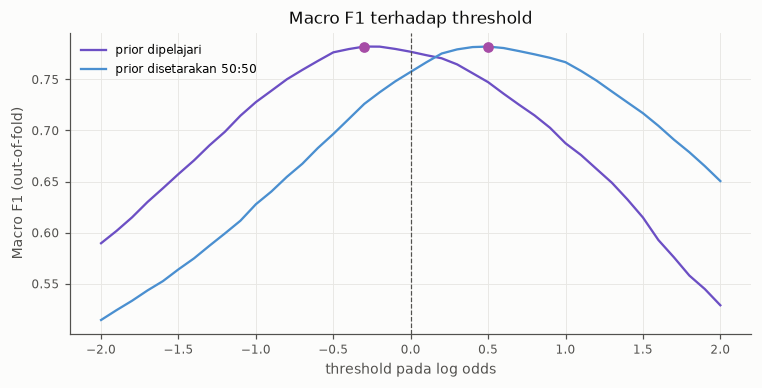

In [21]:
spec_final = final_spec()
learned = evaluate(spec_final, 'prior dipelajari')
equal = evaluate(spec_final, 'prior disetarakan 50:50', class_prior=[0.5, 0.5])
display(table([learned, equal]))

thresholds = np.round(np.arange(-2.0, 2.0001, 0.1), 2)
fig, ax = plt.subplots(figsize=(7, 3.6))
for result, color in ((learned, CFG.POS_COLOR), (equal, CFG.NEG_COLOR)):
    curve = [macro_f1(y, (result['_odds'] > t).astype(int)) for t in thresholds]
    ax.plot(thresholds, curve, color=color, label=result['konfigurasi'])
    best = int(np.argmax(curve))
    ax.scatter(thresholds[best], curve[best], color=CFG.ACCENT_COLOR, zorder=3)
ax.axvline(0, color=CFG.MUTED, lw=0.8, ls='--')
ax.set_xlabel('threshold pada log odds'); ax.set_ylabel('Macro F1 (out-of-fold)')
ax.set_title('Macro F1 terhadap threshold'); ax.legend()
save_fig('nb_imbalance')

#### Insights

> Prior yang dipelajari memberi Macro F1 0,7770 dan prior yang disetarakan 0,7573, tetapi pada threshold terbaik yang dipilih dari fold lain keduanya hampir sama (0,7815 dan 0,7821) dengan ROC-AUC sama persis (0,8636). Ini wajar: pada dua kelas, mengganti prior hanya menggeser log odds dengan konstanta, sama seperti menggeser threshold.

> Karena itu tidak diperlukan resampling. Prior dibiarkan apa adanya dan ketidakseimbangan ditangani lewat threshold. Keuntungan threshold kecil (sekitar 0,004 Macro F1 pada kurva di atas), dan threshold -0,2 dipakai karena sesuai dengan rata-rata threshold terbaik pada empat seed (bagian Modeling and Validation, validasi pada beberapa seed).

## Feature Selection

Seleksi memilih atribut yang dipakai model akhir.

Bagian ini memakai seluruh kandidat fitur (`build_pool`) dan fold yang dipelajari sekali, sehingga setiap evaluasi subset hanya membutuhkan satu kali fit model. Pencarian memakai ROC-AUC out-of-fold sebagai kriteria.

In [22]:
t0 = time.perf_counter()
pool = build_pool()
cache = FoldCache(pool, train, y, n_folds=CFG.FOLDS, seed=CFG.SEED)
print(f'{len(pool)} kandidat fitur, cache per fold dibuat dalam {time.perf_counter() - t0:.1f} detik')

40 kandidat fitur, cache per fold dibuat dalam 8.3 detik


### Dependence Diagnostics

Asumsi Naive Bayes ialah fitur saling independen jika kelas diketahui. Ketergantungan diukur dengan Cramér's V antar pasangan fitur kategorikal pada fold pertama. Nilai besar menunjukkan fitur yang menghitung informasi sama dua kali.

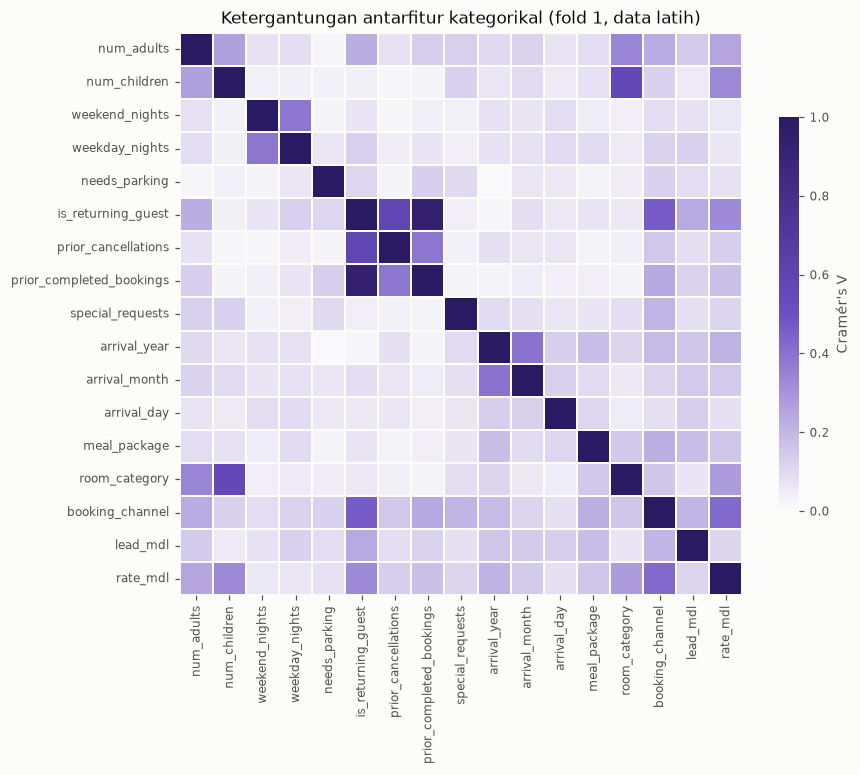

Cramér V
is_returning_guest  prior_completed_bookings     0.932
                    prior_cancellations          0.589
num_children        room_category                0.563
is_returning_guest  booking_channel              0.463
booking_channel     rate_mdl                     0.423
arrival_year        arrival_month                0.396
prior_cancellations prior_completed_bookings     0.389
weekend_nights      weekday_nights               0.388
num_adults          room_category                0.347
num_children        rate_mdl                     0.329

In [23]:
def cramers_v(a, b):
    table_ = pd.crosstab(a, b).to_numpy()
    chi2 = stats.chi2_contingency(table_, correction=False)[0]
    n = table_.sum()
    return float(np.sqrt(chi2 / (n * (min(table_.shape) - 1)))) if min(table_.shape) > 1 else 0.0

X_fit0 = cache.data[0][0]
singles = [n for n in cache.names if not n.startswith('x_') and cache.types[cache.names.index(n)] == 'categorical']
singles = [n for n in singles if n not in ('lead_q5', 'lead_q10', 'rate_q5', 'rate_q10')]
codes = pd.DataFrame({n: X_fit0[:, cache.names.index(n)] for n in singles})
V = pd.DataFrame(index=singles, columns=singles, dtype=float)
for i, a in enumerate(singles):
    for b in singles[i:]:
        V.loc[a, b] = V.loc[b, a] = 1.0 if a == b else cramers_v(codes[a], codes[b])
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(V, cmap=SEQUENTIAL, vmin=0, vmax=1, square=True, linewidths=0.3, linecolor=CFG.SURFACE,
            cbar_kws={'shrink': 0.7, 'label': "Cramér's V"}, ax=ax)
ax.set_title('Ketergantungan antarfitur kategorikal (fold 1, data latih)')
save_fig('nb_dependence')
pairs = V.where(np.triu(np.ones(V.shape), 1).astype(bool)).stack().sort_values(ascending=False)
display(pairs.head(10).round(3).rename('Cramér V').to_frame())

#### Insights

> Pasangan paling bergantung adalah `is_returning_guest` dengan `prior_completed_bookings` (Cramér's V 0,932), disusul `is_returning_guest` dengan `prior_cancellations` (0,589), `num_children` dengan `room_category` (0,563), `is_returning_guest` dengan `booking_channel` (0,463), dan `booking_channel` dengan `rate_mdl` (0,423). Pasangan seperti ini menghitung informasi yang sama dua kali sehingga Naive Bayes menjadi terlalu yakin, dan seleksi fitur sebaiknya hanya mengambil satu dari pasangan itu. `arrival_year` dan `arrival_month` bergantung sedang (0,396), yang mendukung penggabungan keduanya menjadi periode.

### Filter: Mutual Information

Filter menilai tiap fitur sendiri-sendiri terhadap target dengan mutual information $I(X;Y)$ dalam bit, tanpa model. Cepat, tetapi tidak melihat redundansi antarfitur.

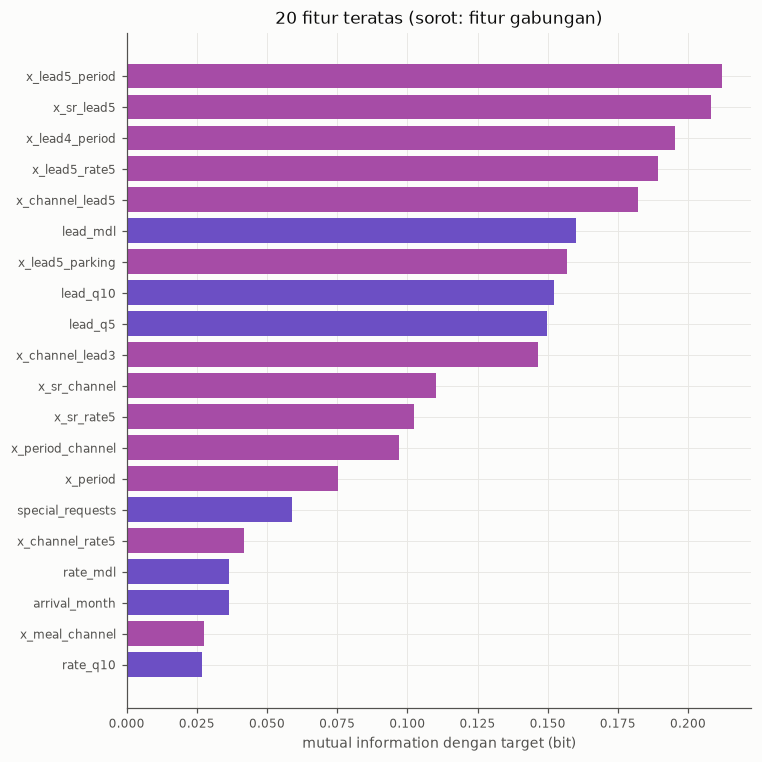

,MI (bit)
lead_q10,0.1523
x_lead5_parking,0.1570
lead_mdl,0.1602
x_channel_lead5,0.1823
x_lead5_rate5,0.1892
x_lead4_period,0.1953
x_sr_lead5,0.2081
x_lead5_period,0.2119


In [24]:
def mutual_information(x, labels):
    joint = pd.crosstab(x, labels).to_numpy().astype(float)
    joint /= joint.sum()
    px, py = joint.sum(axis=1, keepdims=True), joint.sum(axis=0, keepdims=True)
    nz = joint > 0
    return float((joint[nz] * np.log2(joint[nz] / (px @ py)[nz])).sum())

y_fit0 = y[cache.folds[0][0]]
cat_names = [n for n in cache.names if cache.types[cache.names.index(n)] == 'categorical']
mi = pd.Series({n: mutual_information(X_fit0[:, cache.names.index(n)], y_fit0) for n in cat_names}).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(mi.index[-20:], mi.values[-20:], color=[CFG.ACCENT_COLOR if n.startswith('x_') else CFG.POS_COLOR for n in mi.index[-20:]])
ax.set_xlabel('mutual information dengan target (bit)')
ax.set_title('20 fitur teratas (sorot: fitur gabungan)')
save_fig('nb_mutual_information')
display(mi.tail(8).round(4).rename('MI (bit)').to_frame())

#### Insights

> Filter mutual information didominasi fitur gabungan yang melibatkan lead time: `x_lead5_period` (0,2119 bit), `x_sr_lead5` (0,2081), `x_lead4_period` (0,1953), `x_lead5_rate5` (0,1892), dan `x_channel_lead5` (0,1823). Fitur-fitur ini berbagi lead time sehingga redundan satu sama lain, dan fitur dengan banyak sel cenderung memiliki MI lebih tinggi karena bias estimasi. Filter memilih semuanya sekaligus tanpa melihat redundansi, sehingga wrapper di bagian berikutnya lebih tepat.

### Wrapper: Forward Selection

Wrapper memakai model itu sendiri sebagai penilai (Langley dan Sage, 1994). Pada setiap langkah ditambahkan satu fitur yang paling menaikkan ROC-AUC out-of-fold, dan pencarian berhenti ketika tidak ada fitur yang menaikkan ROC-AUC lebih dari $10^{-4}$.

forward selection selesai dalam 33.8 detik


,step,added,macro_f1,macro_f1_held_out_threshold,roc_auc
0,1,x_lead5_period,0.6885,0.7026,0.7868
1,2,x_sr_channel,0.7728,0.7804,0.8537
2,3,rate_mdl,0.7739,0.7793,0.8590
3,4,weekend_nights,0.7762,0.7800,0.8607
4,5,needs_parking,0.7761,0.7800,0.8623
5,6,room_category,0.7768,0.7808,0.8629
6,7,arrival_day,0.7754,0.7824,0.8634
7,8,prior_completed_bookings,0.7770,0.7815,0.8636


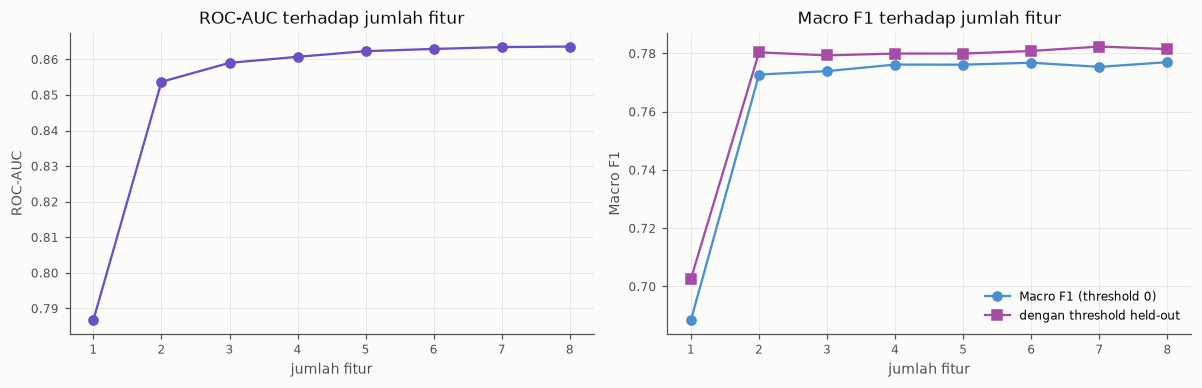

terpilih: ['x_lead5_period', 'x_sr_channel', 'rate_mdl', 'weekend_nights', 'needs_parking', 'room_category', 'arrival_day', 'prior_completed_bookings']
sama dengan FINAL_FEATURES (Helper Pipeline): True


In [25]:
t0 = time.perf_counter()
steps = forward_selection(cache)
forward = pd.DataFrame(steps)
print(f'forward selection selesai dalam {time.perf_counter() - t0:.1f} detik')
display(forward[['step', 'added', 'macro_f1', 'macro_f1_held_out_threshold', 'roc_auc']].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(forward.step, forward.roc_auc, marker='o', color=CFG.POS_COLOR)
axes[0].set_xlabel('jumlah fitur'); axes[0].set_ylabel('ROC-AUC'); axes[0].set_title('ROC-AUC terhadap jumlah fitur')
axes[1].plot(forward.step, forward.macro_f1, marker='o', color=CFG.NEG_COLOR, label='Macro F1 (threshold 0)')
axes[1].plot(forward.step, forward.macro_f1_held_out_threshold, marker='s', color=CFG.ACCENT_COLOR, label='dengan threshold held-out')
axes[1].set_xlabel('jumlah fitur'); axes[1].set_ylabel('Macro F1'); axes[1].set_title('Macro F1 terhadap jumlah fitur')
axes[1].legend()
for ax in axes:
    ax.set_xticks(forward.step)
save_fig('nb_forward_selection')
selected = list(forward.added)
print('terpilih:', selected)
print('sama dengan FINAL_FEATURES (Helper Pipeline):', selected == FINAL_FEATURES)

#### Insights

> Forward selection berhenti pada delapan fitur: `x_lead5_period`, `x_sr_channel`, `rate_mdl`, `weekend_nights`, `needs_parking`, `room_category`, `arrival_day`, dan `prior_completed_bookings`. ROC-AUC naik dari 0,7868 ke 0,8636 dan Macro F1 dari 0,689 ke 0,777. Langkah kedua paling besar (`x_sr_channel`, ROC-AUC 0,8537 dan F1 0,773). Fitur kedua bukan `x_sr_lead5`, padahal MI-nya tinggi, karena sudah berbagi lead time dengan fitur pertama. Setelah langkah ketiga, setiap fitur hanya menaikkan ROC-AUC 0,0002 sampai 0,0017.

> Dari pasangan yang sangat bergantung, hanya `prior_completed_bookings` yang dipilih dan `is_returning_guest` tidak, sejalan dengan peta ketergantungan pada Dependence Diagnostics.

## Dimensionality Reduction

Reduksi dimensi diuji dengan PCA from scratch.

PCA hanya berlaku untuk fitur numerik dan tidak dapat menerima nilai kosong, sehingga diuji pada blok numerik dengan Gaussian NB memakai baris yang lengkap saja (pada data latih maupun validasi di setiap fold). Alasan mencobanya: komponen utama saling tidak berkorelasi, sehingga lebih dekat ke asumsi independensi. Kerugiannya adalah hilangnya interpretasi, dan fitur kategorikal tidak ikut. PCA dipelajari di dalam setiap fold dari data latih, dari SVD matriks yang distandardisasi.

baris lengkap untuk PCA: 18294 dari 27309


,k,roc_auc,macro_f1
0,asli (11 fitur),0.7553,0.6923
1,PCA 1,0.5982,0.4446
2,PCA 2,0.6776,0.4781
3,PCA 3,0.6750,0.5390
4,PCA 4,0.7056,0.5521
5,PCA 6,0.7591,0.6251
6,PCA 8,0.7785,0.6431
7,PCA 11,0.7609,0.4256


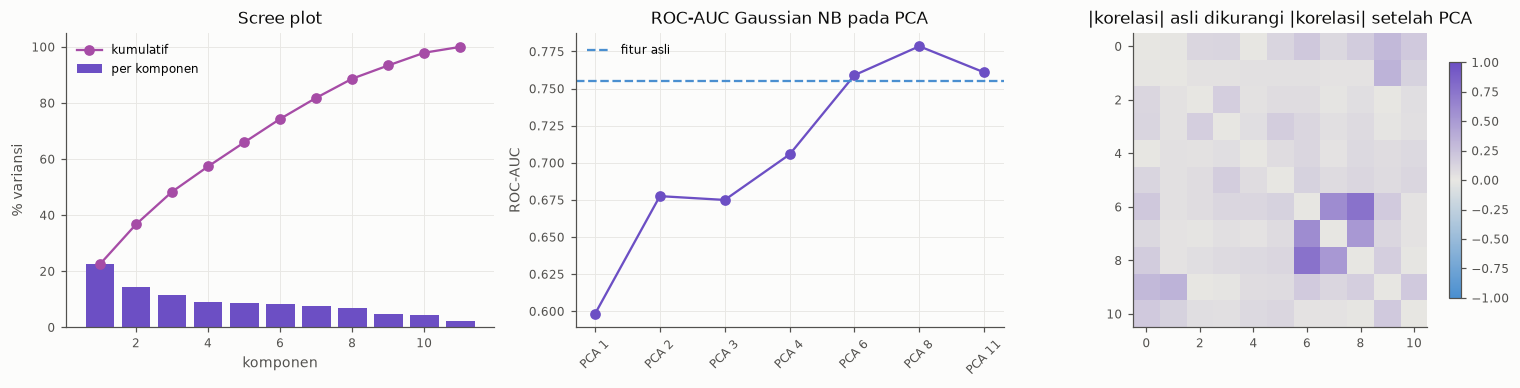

komponen untuk 90% variansi: 9 dari 11
pembanding: pipeline akhir ROC-AUC 0.8636, Macro F1 0.7770


In [26]:
NUMERIC_BLOCK = RAW_NUMERIC
num_spec = {c: 'gauss' for c in NUMERIC_BLOCK}

def pca_cv(k, seed=42):
    folds = stratified_folds(y, CFG.FOLDS, seed)
    auc, f1 = [], []
    for fit_idx, val_idx in folds:
        prep = Preprocessor(num_spec)
        Xf = prep.fit_transform(train.iloc[fit_idx], y[fit_idx]); Xv = prep.transform(train.iloc[val_idx])
        mf, mv = ~np.isnan(Xf).any(axis=1), ~np.isnan(Xv).any(axis=1)
        Xf, yf, Xv, yv = Xf[mf], y[fit_idx][mf], Xv[mv], y[val_idx][mv]
        if k is not None:
            mean, scale, comps, _ = pca_fit(Xf, k)
            Xf, Xv = pca_transform(Xf, mean, scale, comps), pca_transform(Xv, mean, scale, comps)
        model = NaiveBayes().fit(Xf, yf, ['gaussian'] * Xf.shape[1])
        auc.append(roc_auc(yv, model.decision_function(Xv)))
        f1.append(macro_f1(yv, model.predict(Xv, threshold=-0.2).astype(int)))
    return float(np.mean(auc)), float(np.mean(f1))

prep_all = Preprocessor(num_spec).fit(train, y)
X_all = prep_all.transform(train)
X_all = X_all[~np.isnan(X_all).any(axis=1)]
print(f'baris lengkap untuk PCA: {len(X_all)} dari {len(train)}')
_, _, _, ratio = pca_fit(X_all)
ks = [1, 2, 3, 4, 6, 8, len(NUMERIC_BLOCK)]
base_auc, base_f1 = pca_cv(None)
pca_rows = [{'k': 'asli (' + str(len(NUMERIC_BLOCK)) + ' fitur)', 'roc_auc': base_auc, 'macro_f1': base_f1}]
for k in ks:
    auc_k, f1_k = pca_cv(k)
    pca_rows.append({'k': f'PCA {k}', 'roc_auc': auc_k, 'macro_f1': f1_k})
pca_table = pd.DataFrame(pca_rows)
display(pca_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].bar(range(1, len(ratio) + 1), ratio * 100, color=CFG.POS_COLOR, label='per komponen')
axes[0].plot(range(1, len(ratio) + 1), np.cumsum(ratio) * 100, color=CFG.ACCENT_COLOR, marker='o', label='kumulatif')
axes[0].set_xlabel('komponen'); axes[0].set_ylabel('% variansi'); axes[0].set_title('Scree plot'); axes[0].legend()
axes[1].plot(pca_table.k[1:], pca_table.roc_auc[1:], marker='o', color=CFG.POS_COLOR)
axes[1].axhline(pca_table.roc_auc[0], color=CFG.NEG_COLOR, ls='--', label='fitur asli')
axes[1].tick_params(axis='x', rotation=45); axes[1].set_ylabel('ROC-AUC'); axes[1].set_title('ROC-AUC Gaussian NB pada PCA'); axes[1].legend()
corr_raw = np.corrcoef(X_all, rowvar=False)
mean, scale, comps, _ = pca_fit(X_all, len(NUMERIC_BLOCK))
corr_pca = np.corrcoef(pca_transform(X_all, mean, scale, comps), rowvar=False)
im = axes[2].imshow(np.abs(corr_raw) - np.abs(corr_pca), cmap=DIVERGING, vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[2], shrink=0.8)
axes[2].set_title('|korelasi| asli dikurangi |korelasi| setelah PCA'); axes[2].grid(False)
save_fig('nb_pca')
print(f'komponen untuk 90% variansi: {int(np.searchsorted(np.cumsum(ratio), 0.9) + 1)} dari {len(ratio)}')
print(f"pembanding: pipeline akhir ROC-AUC {learned['roc_auc']:.4f}, Macro F1 {learned['macro_f1']:.4f}")

#### Insights

> PCA tidak membantu. Pada 18.294 dari 27.309 baris yang lengkap, Gaussian NB pada 11 fitur numerik asli memberi ROC-AUC 0,7553 dan Macro F1 0,6923. PCA dengan 8 komponen menaikkan ROC-AUC ke 0,7785 tetapi menurunkan Macro F1 menjadi 0,6431. Dengan seluruh 11 komponen Macro F1 anjlok ke 0,4256, dan komponen sedikit (1 sampai 4) jauh lebih buruk dalam keduanya.

> Dibutuhkan 9 dari 11 komponen untuk 90% variansi, sehingga reduksi dimensi tidak banyak menyederhanakan data ini. PCA membuat komponen saling tidak berkorelasi secara linear, tetapi ketergantungan yang merusak Naive Bayes di sini bersifat nonlinear dan melibatkan fitur kategorikal yang tidak ikut PCA. Seluruh blok numerik Gaussian juga jauh di bawah pipeline akhir (ROC-AUC 0,8636 dan F1 0,7770), walaupun perbandingan ini tidak sepenuhnya setara karena PCA hanya memakai baris yang lengkap. PCA tidak dipakai.

---

# Preparation Pipeline <a name="6"></a>

---

Pipeline menggabungkan langkah preparation supaya berjalan dalam satu urutan yang konsisten: `Preprocessor` (kelas di `preprocessing.py`) mempelajari kategori, titik potong MDL, kuantil, dan batas dari data latih, lalu mengubah data apa pun dengan statistik yang sama. Urutannya: gabung kategori langka menjadi `lainnya`, diskretisasi, gabung kolom menjadi fitur gabungan, lalu beri kode bilangan bulat. Nilai kosong dibiarkan sebagai `NaN` dan dilewati model.

`MODELS` memuat konfigurasi akhir tiap model. `fit_pipeline` melatih preprocessor dan model bersama pada satu `DataFrame`.

In [27]:
MODELS = {
    'nb': {'cls': NaiveBayes, 'alpha': 1.0, 'threshold': -0.2},
    'tan': {'cls': TANNaiveBayes, 'alpha': 0.5, 'threshold': -0.2},
}
ALPHA_GRID = (0.5, 1.0, 2.0)
THRESHOLD_GRID = np.round(np.arange(-4.0, 4.0001, 0.1), 2)
FINAL_ALPHA = MODELS['nb']['alpha']
FINAL_THRESHOLD = MODELS['nb']['threshold']

def fit_pipeline(model_name, df):
    config = MODELS[model_name]
    labels = df[TARGET].to_numpy()
    prep = Preprocessor(final_spec()).fit(df, labels)
    model = config['cls'](alpha=config['alpha']).fit(prep.transform(df), labels, prep.feature_types_)
    return prep, model

In [28]:
prep_split = Preprocessor(final_spec()).fit(train_set, y_train)
X_train_set = prep_split.transform(train_set)
X_val_set = prep_split.transform(val_set)
X_test = prep_split.transform(test)

shapes = pd.DataFrame({
    'baris': [len(X_train_set), len(X_val_set), len(X_test)],
    'fitur': [X_train_set.shape[1]] * 3,
    '% baris dengan fitur dilewati': [np.isnan(X).any(axis=1).mean() * 100 for X in (X_train_set, X_val_set, X_test)],
}, index=['train_set', 'val_set', 'test']).round(2)
display(shapes)
print('fitur akhir:', prep_split.feature_names_)
print('titik potong MDL tarif:', [round(c, 0) for c in prep_split.parts_['rate_mdl']['subs'][0].cuts_['nightly_rate_idr']])

,baris,fitur,% baris dengan fitur dilewati
train_set,24577,8,25.23
val_set,2732,8,25.04
test,6844,8,24.90


fitur akhir: ['x_lead5_period', 'x_sr_channel', 'rate_mdl', 'weekend_nights', 'needs_parking', 'room_category', 'arrival_day', 'prior_completed_bookings']
titik potong MDL tarif: [765500.0, 1190500.0, 1504500.0, 1639500.0, 1813500.0, 1954500.0, 2224500.0, 3327000.0]


#### Insights

> Pipeline menghasilkan delapan fitur kategorikal dengan bentuk yang sama untuk `train_set`, `val_set`, dan test. Porsi baris yang memiliki setidaknya satu fitur dilewati hampir sama di ketiganya (25,23%, 25,04%, dan 24,90%), sehingga pola nilai kosong pada test mirip dengan data latih dan marginalisasi bekerja dengan cara yang sama.

> Titik potong MDL untuk tarif dipelajari dari `train_set` saja: delapan titik potong (sembilan kelompok), dari 765.500 sampai 3.327.000. `val_set` dan test hanya diubah dengan titik potong itu.

---

# Modeling and Validation <a name="7"></a>

---

Target adalah `is_canceled`. Model di bagian ini ditulis from scratch dengan NumPy (`nb.py` dan `tan.py`), dan tidak ada kelas scikit-learn yang dipakai untuk menghitung peluangnya.

## Naive Bayes

Bagian ini mencakup kontribusi tiap tahap preparation, validasi, dan estimasi hold-out untuk Naive Bayes.

### Kontribusi Tiap Tahap Preprocessing

Pipeline dibangun bertahap, dan setiap tahap dinilai dengan Stratified 5-Fold yang sama, sehingga kontribusi tiap keputusan terlihat.

,konfigurasi,macro_f1,std,f1_threshold_held_out,roc_auc
0,1 Gaussian pada fitur mentah,0.6926,0.0092,0.6917,0.7792
1,2 hitungan sebagai kategori,0.7122,0.0109,0.7257,0.8143
2,3 lead dan tarif didiskretisasi,0.7253,0.0110,0.7324,0.8211
3,4 + periode kedatangan,0.7466,0.0074,0.7474,0.8361
4,5 + fitur gabungan,0.7702,0.0067,0.7725,0.8565
5,6 seleksi fitur forward,0.7770,0.0051,0.7815,0.8636


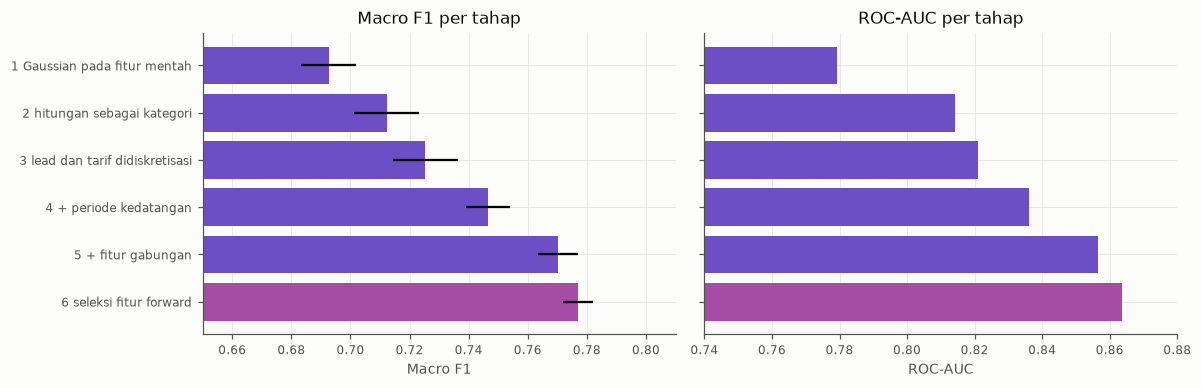

In [29]:
raw_spec = {c: 'gauss' for c in RAW_NUMERIC}
raw_spec.update({c: 'cat' for c in RAW_CATEGORICAL})
raw_spec.update({'arrival_month': 'cat', 'arrival_year': 'cat', 'arrival_day': 'cat'})
stages = [
    ('1 Gaussian pada fitur mentah', raw_spec),
    ('2 hitungan sebagai kategori', {**{c: 'cat' for c in COUNTS + RAW_CATEGORICAL},
                                     'days_before_arrival': 'gauss', 'nightly_rate_idr': 'gauss'}),
    ('3 lead dan tarif didiskretisasi', base_spec()),
    ('4 + periode kedatangan', add(base_spec(), 'x_period')),
    ('5 + fitur gabungan', add(base_spec(), 'x_lead5_period', 'x_sr_channel')),
    ('6 seleksi fitur forward', final_spec()),
]
stage_rows = [evaluate(spec, label) for label, spec in stages]
stage_table = table(stage_rows)
display(stage_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
colors = [CFG.POS_COLOR] * (len(stage_rows) - 1) + [CFG.ACCENT_COLOR]
axes[0].barh(stage_table.konfigurasi[::-1], stage_table.macro_f1[::-1], xerr=stage_table['std'][::-1], color=colors[::-1])
axes[0].set_xlim(0.65, 0.81); axes[0].set_xlabel('Macro F1'); axes[0].set_title('Macro F1 per tahap')
axes[1].barh(stage_table.konfigurasi[::-1], stage_table.roc_auc[::-1], color=colors[::-1])
axes[1].set_xlim(0.74, 0.88); axes[1].set_xlabel('ROC-AUC'); axes[1].set_title('ROC-AUC per tahap'); axes[1].set_yticklabels([])
save_fig('nb_ablation')

#### Insights

> Setiap tahap menaikkan Macro F1 dan ROC-AUC: Macro F1 0,6926 (Gaussian mentah), 0,7122 (hitungan sebagai kategori), 0,7253 (diskretisasi), 0,7466 (periode kedatangan), 0,7702 (fitur gabungan), dan 0,7770 (seleksi forward), dengan ROC-AUC dari 0,7792 menjadi 0,8636. Kenaikan terbesar berasal dari fitur gabungan (0,024) dan periode kedatangan (0,021), diikuti hitungan sebagai kategori (0,020) dan diskretisasi (0,013). Seleksi fitur memberi kenaikan terkecil (0,007) tetapi menurunkan jumlah fitur.

### Validasi pada Beberapa Seed

Pemilihan fitur memakai fold dengan seed 42. Untuk memeriksa apakah hasilnya bergantung pada pembagian itu, model akhir dievaluasi ulang pada seed lain. Threshold dipilih dari fold lain dan dinilai pada fold yang tidak ikut memilihnya.

In [30]:
seed_rows = []
for seed in CFG.CHECK_SEEDS:
    r = cross_validate(final_spec(), NaiveBayes, train, y, n_folds=CFG.FOLDS, seed=seed)
    seed_rows.append({'seed': seed, 'macro_f1': r['macro_f1'], 'std_fold': r['macro_f1_std'],
                      'f1_threshold_held_out': r['macro_f1_held_out_threshold'],
                      'best_threshold': r['best_threshold'], 'roc_auc': r['roc_auc']})
seed_table = pd.DataFrame(seed_rows).round(4)
display(seed_table)
print(f"rata-rata Macro F1 {seed_table.macro_f1.mean():.4f}, dengan threshold held-out "
      f"{seed_table.f1_threshold_held_out.mean():.4f}, threshold terbaik rata-rata "
      f"{seed_table.best_threshold.mean():+.2f} (dipakai FINAL_THRESHOLD = {FINAL_THRESHOLD})")

,seed,macro_f1,std_fold,f1_threshold_held_out,best_threshold,roc_auc
0,42,0.7770,0.0051,0.7815,-0.3,0.8636
1,7,0.7776,0.0041,0.7788,-0.2,0.8639
2,2026,0.7782,0.0060,0.7823,-0.2,0.8634
3,99,0.7786,0.0050,0.7815,-0.2,0.8635


rata-rata Macro F1 0.7778, dengan threshold held-out 0.7810, threshold terbaik rata-rata -0.22 (dipakai FINAL_THRESHOLD = -0.2)


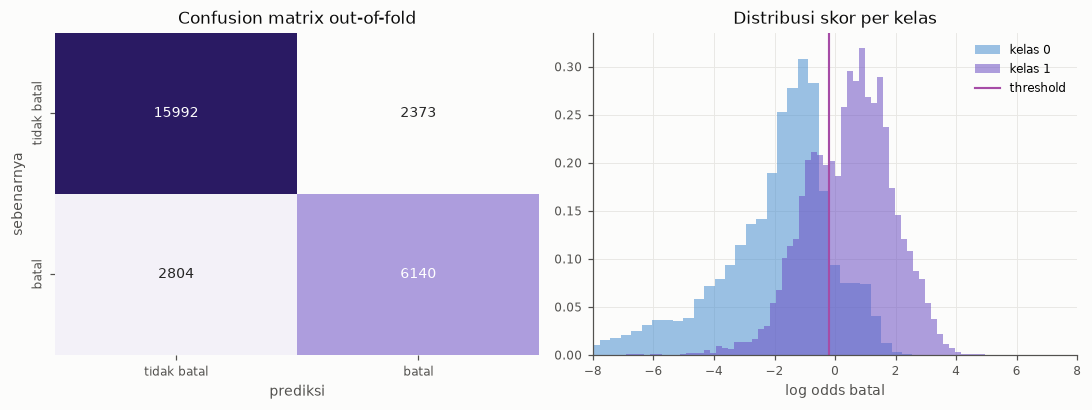

kelas batal: presisi 0.721, recall 0.686


In [31]:
odds = learned['_odds']
pred = (odds > FINAL_THRESHOLD).astype(int)
cm = confusion_matrix(y, pred)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap=SEQUENTIAL, cbar=False, ax=axes[0],
            xticklabels=['tidak batal', 'batal'], yticklabels=['tidak batal', 'batal'])
axes[0].set_xlabel('prediksi'); axes[0].set_ylabel('sebenarnya'); axes[0].set_title('Confusion matrix out-of-fold'); axes[0].grid(False)
for cls, color in ((0, CFG.NEG_COLOR), (1, CFG.POS_COLOR)):
    axes[1].hist(odds[y == cls], bins=60, alpha=0.55, color=color, density=True, label=f'kelas {cls}')
axes[1].axvline(FINAL_THRESHOLD, color=CFG.ACCENT_COLOR, lw=1.4, label='threshold')
axes[1].set_xlim(-8, 8); axes[1].set_xlabel('log odds batal'); axes[1].set_title('Distribusi skor per kelas'); axes[1].legend()
save_fig('nb_confusion')
precision = cm[1, 1] / cm[:, 1].sum(); recall = cm[1, 1] / cm[1].sum()
print(f'kelas batal: presisi {precision:.3f}, recall {recall:.3f}')

#### Insights

> Hasil stabil pada empat seed: Macro F1 0,7770, 0,7776, 0,7782, dan 0,7786 (rata-rata 0,7778), dengan simpangan baku antar fold 0,004 sampai 0,006. Dengan threshold yang dipilih dari fold lain, rata-rata menjadi 0,7810, dan threshold terbaik rata-rata -0,22. Pada kelas batal, presisi 0,721 dan recall 0,686. Perlu diingat bahwa seed berbeda memakai data yang sama dengan pemilihan fitur, sehingga bagian berikut menghitung estimasi yang tidak bias.

### Hold-out: Estimasi Tanpa Bias Seleksi

Seed berbeda pada bagian sebelumnya memakai data yang sama dengan pemilihan fitur, sehingga bukan estimasi independen. Untuk memeriksanya, 10% data disisihkan sebelum apa pun dipelajari (`val_set` pada bagian Training and Validation Split). Seleksi fitur diulang dari awal hanya pada 90% sisanya, lalu model dinilai pada 10% yang tidak pernah dilihat.

In [32]:
cache_dev = FoldCache(pool, train_set, y_train, n_folds=CFG.FOLDS, seed=CFG.SEED)
selected_dev = [s['added'] for s in forward_selection(cache_dev)]
print('terpilih pada 90%:', selected_dev)
print('sama dengan pemilihan pada seluruh data:', selected_dev == FINAL_FEATURES)

prep_dev = Preprocessor({n: pool[n] for n in selected_dev}).fit(train_set, y_train)
model_dev = NaiveBayes(alpha=FINAL_ALPHA).fit(prep_dev.transform(train_set), y_train, prep_dev.feature_types_)
X_hold = prep_dev.transform(val_set)
odds_hold = model_dev.decision_function(X_hold)
hold = pd.DataFrame([{
    'baris hold-out': len(val_set),
    'macro_f1 (threshold 0)': macro_f1(y_val, (odds_hold > 0).astype(int)),
    f'macro_f1 (threshold {FINAL_THRESHOLD})': macro_f1(y_val, (odds_hold > FINAL_THRESHOLD).astype(int)),
    'roc_auc': roc_auc(y_val, odds_hold)}]).round(4)
display(hold)

terpilih pada 90%: ['x_lead5_period', 'x_sr_channel', 'rate_mdl', 'weekend_nights', 'needs_parking', 'arrival_day', 'num_children', 'prior_completed_bookings', 'room_category']
sama dengan pemilihan pada seluruh data: False


,baris hold-out,macro_f1 (threshold 0),macro_f1 (threshold -0.2),roc_auc
0,2732,0.772,0.7757,0.8584


#### Insights

> Seleksi forward yang diulang hanya pada 90% data memilih sembilan fitur, yaitu delapan fitur yang sama ditambah `num_children`. Jadi pemilihan fitur tidak sepenuhnya stabil: fitur-fitur pinggiran yang kontribusinya sangat kecil bisa berganti. Fitur inti (`x_lead5_period`, `x_sr_channel`, `rate_mdl`) tidak berubah.

> Pada 2.732 baris hold-out yang tidak pernah dilihat, Macro F1 adalah 0,7720 pada threshold 0 dan 0,7757 pada threshold -0,2, dengan ROC-AUC 0,8584. Angka ini sedikit di bawah validasi silang (Macro F1 0,7770 dan ROC-AUC 0,8636), selisih yang masuk akal oleh derau satu hold-out sebesar 10% (simpangan baku antar fold sekitar 0,005) dan sedikit bias seleksi. Estimasi yang jujur untuk skor test adalah sekitar 0,775.

## Cost-Sensitive Classification

Sel berikut menetapkan biaya kesalahan (FP dua kali FN) dan aturan keputusan teoretisnya.

In [33]:
COST_FP = 2.0
COST_FN = 1.0
COST_THRESHOLD = float(np.log(COST_FP / COST_FN))

def expected_cost(y_true, y_pred, c_fp=COST_FP, c_fn=COST_FN):
    false_positive = np.sum((y_pred == 1) & (y_true == 0))
    false_negative = np.sum((y_pred == 0) & (y_true == 1))
    return float((c_fp * false_positive + c_fn * false_negative) / len(y_true))

Tidak semua kesalahan sama mahalnya. **False Positive** (diprediksi batal, tamu datang) membuat kamar dijual ulang sehingga hotel overbooked, sedangkan **False Negative** (diprediksi datang, tamu batal) hanya membuat kamar kosong. Dengan asumsi FP dua kali lebih mahal dari FN ($c_{FP} = 2$, $c_{FN} = 1$) dan kelas batal sebagai positif, aturan keputusan Bayes dengan biaya (Elkan, 2001) memprediksi batal hanya jika

$$P(\text{batal} \mid x) > \frac{c_{FP}}{c_{FP} + c_{FN}} = \frac{2}{3}$$

yang pada log odds berarti threshold $\log 2 \approx 0{,}693$, bukan 0 seperti pada Macro F1. Metrik yang dipakai adalah biaya rata-rata per baris:

$$\text{biaya} = \frac{c_{FP} \cdot FP + c_{FN} \cdot FN}{n}$$

Tiga aturan dibandingkan: threshold untuk Macro F1 (-0,2), threshold teoretis $\log 2$, dan threshold yang meminimalkan biaya pada kurva validasi silang. Pengubahan ini hanya menggeser aturan keputusan, bukan modelnya.

,seed,aturan,threshold,biaya,macro_f1,FP,FN
0,42,threshold Macro F1,-0.2000,0.2765,0.7821,2373,2804
1,42,threshold teoretis log 2,0.6931,0.2487,0.7256,1029,4733
2,42,threshold biaya terbaik,0.9000,0.2464,0.7026,730,5269
3,7,threshold Macro F1,-0.2000,0.2783,0.7812,2399,2803
4,7,threshold teoretis log 2,0.6931,0.2458,0.7279,1000,4713
5,7,threshold biaya terbaik,0.9000,0.2460,0.7026,722,5273
6,2026,threshold Macro F1,-0.2000,0.2762,0.7823,2372,2799
7,2026,threshold teoretis log 2,0.6931,0.2472,0.7267,1014,4724
8,2026,threshold biaya terbaik,0.8000,0.2461,0.7154,862,4996
9,99,threshold Macro F1,-0.2000,0.2767,0.7820,2378,2801


,threshold,biaya,macro_f1,FP,FN
aturan,,,,,
threshold Macro F1,-0.2000,0.2769,0.7819,2380.50,2801.75
threshold biaya terbaik,0.8000,0.2460,0.7147,858.25,5001.75
threshold teoretis log 2,0.6931,0.2470,0.7269,1010.75,4722.50


pembanding biaya: {'semua tidak batal': 0.3275, 'semua batal': 1.345}


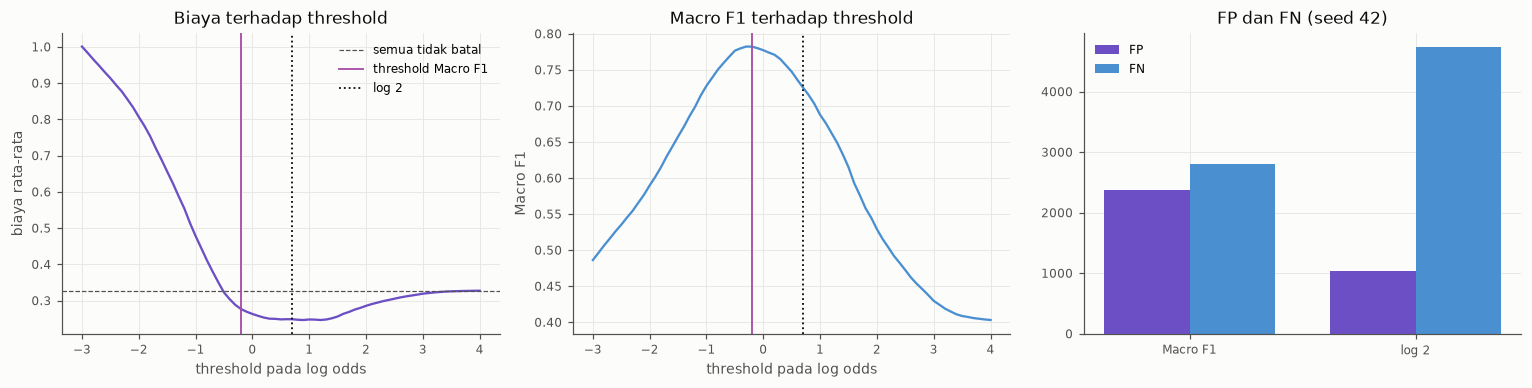

In [34]:
thresholds_cost = np.round(np.arange(-3.0, 4.0001, 0.1), 2)
rows = []
for seed in CFG.CHECK_SEEDS:
    r = cross_validate(final_spec(), NaiveBayes, train, y, n_folds=CFG.FOLDS, seed=seed)
    odds_s = r['odds']
    folds_s = stratified_folds(y, CFG.FOLDS, seed)
    curves = np.array([[expected_cost(y[v], (odds_s[v] > t).astype(int)) for t in thresholds_cost] for _, v in folds_s])
    best_t = float(thresholds_cost[int(np.argmin(curves.mean(axis=0)))])
    for label, t in (('threshold Macro F1', FINAL_THRESHOLD), ('threshold teoretis log 2', COST_THRESHOLD),
                     ('threshold biaya terbaik', best_t)):
        pred = (odds_s > t).astype(int)
        rows.append({'seed': seed, 'aturan': label, 'threshold': t, 'biaya': expected_cost(y, pred),
                     'macro_f1': macro_f1(y, pred), 'FP': int(((pred == 1) & (y == 0)).sum()),
                     'FN': int(((pred == 0) & (y == 1)).sum())})
cost_table = pd.DataFrame(rows)
baseline = {'semua tidak batal': expected_cost(y, np.zeros_like(y)), 'semua batal': expected_cost(y, np.ones_like(y))}
display(cost_table.round(4))
display(cost_table.groupby('aturan')[['threshold', 'biaya', 'macro_f1', 'FP', 'FN']].mean().round(4))
print('pembanding biaya:', {k: round(v, 4) for k, v in baseline.items()})

odds42 = learned['_odds']
cost_curve = [expected_cost(y, (odds42 > t).astype(int)) for t in thresholds_cost]
f1_curve = [macro_f1(y, (odds42 > t).astype(int)) for t in thresholds_cost]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(thresholds_cost, cost_curve, color=CFG.POS_COLOR)
axes[0].axhline(baseline['semua tidak batal'], color=CFG.MUTED, ls='--', lw=0.8, label='semua tidak batal')
axes[1].plot(thresholds_cost, f1_curve, color=CFG.NEG_COLOR)
for ax, title, ylabel in ((axes[0], 'Biaya terhadap threshold', 'biaya rata-rata'), (axes[1], 'Macro F1 terhadap threshold', 'Macro F1')):
    ax.axvline(FINAL_THRESHOLD, color=CFG.ACCENT_COLOR, lw=1.2, label='threshold Macro F1')
    ax.axvline(COST_THRESHOLD, color=CFG.INK, lw=1.2, ls=':', label='log 2')
    ax.set_xlabel('threshold pada log odds'); ax.set_ylabel(ylabel); ax.set_title(title)
axes[0].legend()
pick = cost_table[(cost_table.seed == CFG.SEED) & cost_table.aturan.isin(['threshold Macro F1', 'threshold teoretis log 2'])]
xs = np.arange(len(pick)); width = 0.38
axes[2].bar(xs - width / 2, pick.FP, width, color=CFG.POS_COLOR, label='FP')
axes[2].bar(xs + width / 2, pick.FN, width, color=CFG.NEG_COLOR, label='FN')
axes[2].set_xticks(xs); axes[2].set_xticklabels(['Macro F1', 'log 2']); axes[2].set_title('FP dan FN (seed 42)'); axes[2].legend()
save_fig('nb_cost_sensitive')

#### Insights

> Dengan threshold teoretis log 2, biaya rata-rata turun dari 0,2769 (threshold untuk Macro F1) menjadi 0,2470, atau sekitar 10,8% lebih murah (rata-rata empat seed). Jumlah FP turun dari sekitar 2.380 menjadi 1.011 (turun 58%), sedangkan FN naik dari sekitar 2.802 menjadi 4.723. Itu sesuai tujuan: lebih banyak tamu yang diprediksi datang, sehingga lebih sedikit kamar yang dijual ulang secara keliru, dengan harga lebih banyak kamar yang kosong. Pembanding tanpa model, memprediksi semua tidak batal, berbiaya 0,3275, jadi aturan ini sekitar 24,6% di bawahnya.

> Harganya pada metrik kompetisi: Macro F1 turun dari 0,7819 menjadi 0,7269 (selisih sekitar 0,055; angka ini dihitung dari gabungan prediksi out-of-fold sehingga sedikit berbeda dari rata-rata per fold 0,777 di bagian lain). Threshold yang meminimalkan biaya berkisar antara 0,6 dan 0,9 pada empat seed, dengan biaya 0,2460, hanya 0,0010 lebih murah dari threshold teoretis, dan Macro F1-nya lebih rendah lagi (0,7147). Kurva biaya datar di sekitar minimum, sehingga threshold teoretis log 2 hampir optimal tanpa perlu dituning. Dipakai threshold teoretis supaya tidak ada penyesuaian ke data.

Aturan yang sama diperiksa pada hold-out dari bagian Naive Bayes (Hold-out), yang tidak dipakai untuk memilih fitur maupun threshold.

In [35]:
rows = []
for label, t in (('threshold Macro F1', FINAL_THRESHOLD), ('threshold teoretis log 2', COST_THRESHOLD)):
    pred = (odds_hold > t).astype(int)
    rows.append({'aturan': label, 'threshold': round(t, 3), 'biaya': expected_cost(y_val, pred),
                 'macro_f1': macro_f1(y_val, pred), 'FP': int(((pred == 1) & (y_val == 0)).sum()),
                 'FN': int(((pred == 0) & (y_val == 1)).sum())})
display(pd.DataFrame(rows).round(4))
print('pembanding biaya hold-out, semua tidak batal:', round(expected_cost(y_val, np.zeros(len(y_val), dtype=int)), 4))

,aturan,threshold,biaya,macro_f1,FP,FN
0,threshold Macro F1,-0.200,0.2881,0.7757,252,283
1,threshold teoretis log 2,0.693,0.2504,0.7280,109,466


pembanding biaya hold-out, semua tidak batal: 0.3276


#### Insights

> Pada hold-out 2.732 baris, pola yang sama muncul: biaya turun dari 0,2881 menjadi 0,2504 (sekitar 13% lebih murah) dengan FP turun dari 252 menjadi 109 dan FN naik dari 283 menjadi 466, sedangkan Macro F1 turun dari 0,7757 menjadi 0,7280. Pembanding semua-tidak-batal berbiaya 0,3276, sehingga aturan cost-sensitive sekitar 23,6% di bawahnya dan aturan Macro F1 sekitar 12,1% di bawahnya. Hasil ini tidak dipakai untuk memilih threshold, jadi bersifat independen.

## Optimization: Tree-Augmented Naive Bayes (TAN)

Naive Bayes menganggap fitur saling independen jika kelas diketahui. Bagian Dependence Diagnostics menunjukkan asumsi itu dilanggar. **TAN** (Friedman, Geiger & Goldszmidt, 1997) melonggarkannya sedikit: tiap fitur boleh punya **satu fitur lain sebagai orang tua**, selain kelas. Pohon ketergantungannya dibangun dengan langkah berikut:

1. Hitung *conditional mutual information* untuk setiap pasangan fitur: $I(X_i; X_j \mid C) = \sum P(x_i, x_j, c) \log \frac{P(x_i, x_j \mid c)}{P(x_i \mid c)\,P(x_j \mid c)}$.
2. Cari *maximum spanning tree* dari bobot itu (algoritma Prim, mengikuti Chow dan Liu, 1968).
3. Arahkan pohon dari satu akar. Peluang fitur anak dihitung dari tabel $P(x_j \mid x_{\text{orang tua}}, c)$ dengan smoothing add-$\alpha$.

Model ini memakai fitur yang sama dan preprocessing yang sama dengan Naive Bayes, hanya cara menghitung peluangnya yang berbeda, dan hanya menerima fitur kategorikal. `alpha` dan threshold dipilih dari tabel ablation di bawah (kolom `best_threshold`).

In [36]:
rows = []
for seed in CFG.CHECK_SEEDS:
    for name, cfg in MODELS.items():
        r = cross_validate(final_spec(), cfg['cls'], train, y, n_folds=CFG.FOLDS, seed=seed,
                           model_kwargs={'alpha': cfg['alpha']})
        rows.append({'seed': seed, 'model': name, 'macro_f1': r['macro_f1'],
                     'f1_threshold_held_out': r['macro_f1_held_out_threshold'],
                     'best_threshold': r['best_threshold'], 'roc_auc': r['roc_auc']})
compare_models = pd.DataFrame(rows)
display(compare_models.round(4))
display(compare_models.groupby('model')[['macro_f1', 'f1_threshold_held_out', 'best_threshold', 'roc_auc']].mean().round(4))

ablation = []
for alpha in ALPHA_GRID:
    r = cross_validate(final_spec(), TANNaiveBayes, train, y, n_folds=CFG.FOLDS, seed=CFG.SEED,
                       model_kwargs={'alpha': alpha})
    ablation.append({'alpha': alpha, 'macro_f1': r['macro_f1'], 'f1_threshold_held_out': r['macro_f1_held_out_threshold'],
                     'best_threshold': r['best_threshold'], 'roc_auc': r['roc_auc']})
print('Pengaruh alpha pada TAN (seed 42):')
display(pd.DataFrame(ablation).round(4))

,seed,model,macro_f1,f1_threshold_held_out,best_threshold,roc_auc
0,42,nb,0.7770,0.7815,-0.3,0.8636
1,42,tan,0.8094,0.8103,-0.2,0.9009
2,7,nb,0.7776,0.7788,-0.2,0.8639
3,7,tan,0.8095,0.8099,-0.3,0.9014
4,2026,nb,0.7782,0.7823,-0.2,0.8634
5,2026,tan,0.8082,0.8087,-0.3,0.9010
6,99,nb,0.7786,0.7815,-0.2,0.8635
7,99,tan,0.8081,0.8088,-0.1,0.9005


,macro_f1,f1_threshold_held_out,best_threshold,roc_auc
model,,,,
nb,0.7779,0.7810,-0.225,0.8636
tan,0.8088,0.8094,-0.225,0.9009


Pengaruh alpha pada TAN (seed 42):


,alpha,macro_f1,f1_threshold_held_out,best_threshold,roc_auc
0,0.5,0.8094,0.8103,-0.2,0.9009
1,1.0,0.8091,0.8089,-0.4,0.9010
2,2.0,0.8067,0.8075,-0.5,0.8995


#### Insights

> TAN lebih baik daripada Naive Bayes pada keempat seed. Rata-rata Macro F1 dengan threshold held-out naik dari 0,7810 menjadi 0,8094 (selisih 0,028) dan ROC-AUC dari 0,8636 menjadi 0,9009 (selisih 0,037). Selisihnya konsisten: Macro F1 TAN terendah (0,8087) masih di atas Naive Bayes tertinggi (0,7823), sedangkan variasi antar seed TAN kurang dari 0,002. Threshold terbaik rata-rata sama untuk keduanya (-0,225), jadi kenaikan ini berasal dari modelnya, bukan dari pergeseran threshold.
>
> Pada ablation `alpha`, nilai 0,5 memberi Macro F1 tertinggi (0,8103) dan ROC-AUC 0,9009, sedangkan `alpha` 1,0 memberi AUC yang praktis sama (0,9010) dan `alpha` 2,0 sedikit lebih rendah (0,8075 dan 0,8995). Perbedaan antar `alpha` paling besar 0,003 pada Macro F1, jauh lebih kecil daripada selisih terhadap Naive Bayes (0,028), jadi hasil TAN tidak bergantung pada pilihan `alpha`. Threshold terbaiknya bergeser dari -0,2 ke -0,5 ketika `alpha` naik. Catatan: `alpha` dipilih pada data yang sama dengan evaluasi sehingga angkanya sedikit optimistis, tetapi selisih sebesar ini jauh melampaui pengaruh pemilihan `alpha`.

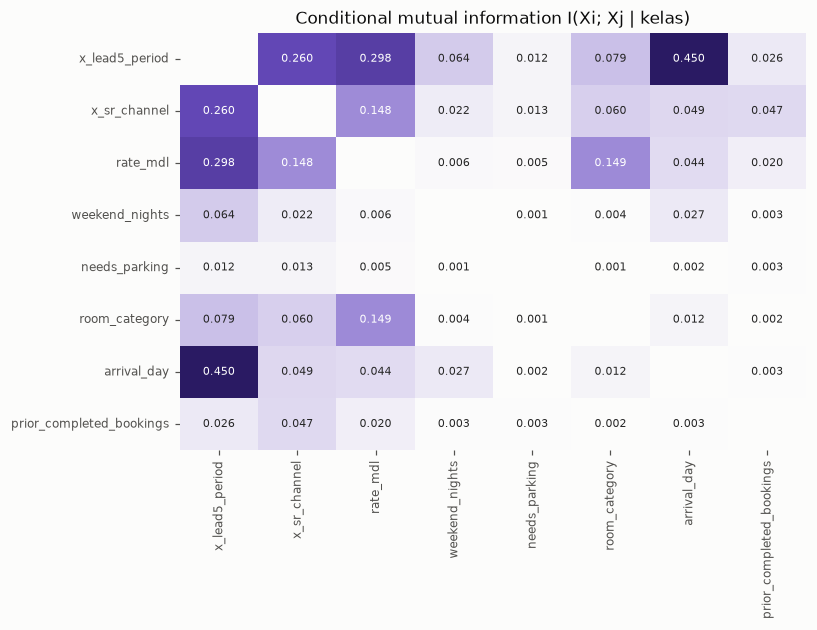

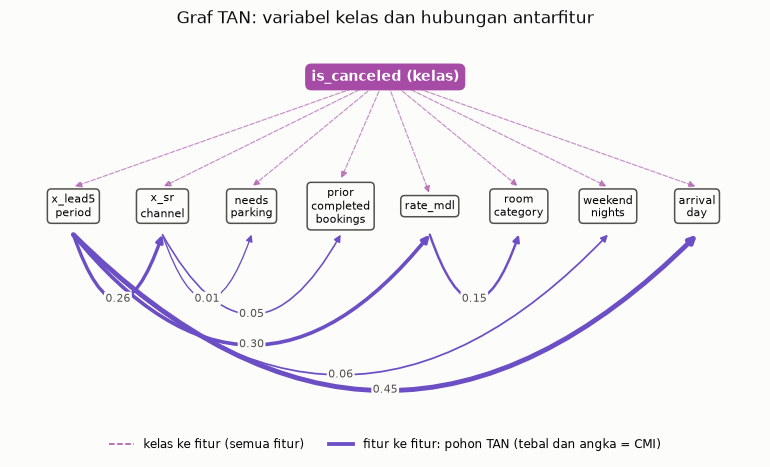

,orang tua,anak,CMI
5,x_lead5_period,arrival_day,0.4500
1,x_lead5_period,rate_mdl,0.2982
0,x_lead5_period,x_sr_channel,0.2604
4,rate_mdl,room_category,0.1489
2,x_lead5_period,weekend_nights,0.0645
6,x_sr_channel,prior_completed_bookings,0.0472
3,x_sr_channel,needs_parking,0.0126


In [37]:
prep_tan, tan_model = fit_pipeline('tan', train)
names = prep_tan.feature_names_
cmi = tan_model.weights_.copy()
parent = tan_model.parent_
cmi_plot = np.where(np.isinf(cmi), np.nan, cmi)

# fitur diurutkan dengan penelusuran pohon dari akar, supaya busur antarfitur tidak saling memotong
children = {j: [c for c in range(len(names)) if parent[c] == j] for j in range(len(names))}
order = []
def visit(j):
    order.append(j)
    for c in children[j]:
        visit(c)
visit(int(np.flatnonzero(parent < 0)[0]))
x_of = {j: float(k) for k, j in enumerate(order)}

def wrap(name, width=9):
    lines, cur = [], ''
    for token in name.split('_'):
        candidate = token if not cur else cur + '_' + token
        if cur and len(candidate) > width:
            lines.append(cur)
            cur = token
        else:
            cur = candidate
    lines.append(cur)
    return chr(10).join(lines)

n_feat = len(names)
class_xy = ((n_feat - 1) / 2, 1.45)
fig, ax = plt.subplots(figsize=(7.5, 5.8))
sns.heatmap(cmi_plot, annot=True, fmt='.3f', cmap=SEQUENTIAL, cbar=False, ax=ax,
            xticklabels=names, yticklabels=names, annot_kws={'size': 7})
ax.set_title('Conditional mutual information I(Xi; Xj | kelas)'); ax.grid(False)
save_fig('nb_tan_cmi')

fig, ax = plt.subplots(figsize=(10.5, 4.3))
box_class = ax.text(*class_xy, 'is_canceled (kelas)', ha='center', va='center', fontsize=9, fontweight='bold',
                    color='white', bbox=dict(boxstyle='round,pad=0.4', fc=CFG.ACCENT_COLOR, ec=CFG.ACCENT_COLOR), zorder=5)
boxes = {j: ax.text(x_of[j], 0, wrap(names[j]), ha='center', va='center', fontsize=7.5, linespacing=1.15,
                    bbox=dict(boxstyle='round,pad=0.35', fc=CFG.SURFACE, ec=CFG.MUTED), zorder=5) for j in range(n_feat)}
ax.set_xlim(-0.7, n_feat - 0.3); ax.set_ylim(-2.6, 1.95); ax.set_aspect('equal'); ax.axis('off')
fig.canvas.draw()
to_data = ax.transData.inverted()
for j in range(n_feat):  # kelas ke setiap fitur: garis lurus ke tengah sisi atas kotak fitur
    box = boxes[j].get_bbox_patch().get_window_extent()
    top = to_data.transform((box.x0 + box.width / 2, box.y1))
    ax.annotate('', xy=(x_of[j], top[1]), xytext=class_xy, zorder=1, arrowprops=dict(
        arrowstyle='-|>', color=CFG.ACCENT_COLOR, lw=0.8, alpha=0.6, linestyle='--',
        patchA=box_class.get_bbox_patch(), shrinkA=2, shrinkB=1))
for child, p in enumerate(parent):  # pohon TAN: busur di bawah baris fitur
    if p < 0:
        continue
    x1, x2 = x_of[p], x_of[child]
    dx = x2 - x1
    y_edge = -0.32  # tepi bawah kotak fitur
    height = 0.55 + 0.17 * abs(dx)
    rad = 2 * height / abs(dx) * (1 if dx > 0 else -1)
    ax.annotate('', xy=(x2, y_edge), xytext=(x1, y_edge), zorder=2, arrowprops=dict(
        arrowstyle='-|>', color=CFG.POS_COLOR, lw=0.8 + 2.4 * cmi[p, child] / np.nanmax(cmi_plot), shrinkA=0, shrinkB=0,
        connectionstyle='arc3,rad=' + str(rad)))
    ax.text((x1 + x2) / 2, y_edge - height, f'{cmi[p, child]:.2f}', fontsize=7.5, color=CFG.MUTED, ha='center', va='center',
            zorder=6, bbox=dict(boxstyle='round,pad=0.12', fc=CFG.SURFACE, ec='none'))
ax.plot([], [], color=CFG.ACCENT_COLOR, ls='--', lw=1, label='kelas ke fitur (semua fitur)')
ax.plot([], [], color=CFG.POS_COLOR, lw=2.5, label='fitur ke fitur: pohon TAN (tebal dan angka = CMI)')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=8, frameon=False)
ax.set_xlim(-0.7, n_feat - 0.3); ax.set_ylim(-2.6, 1.95); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Graf TAN: variabel kelas dan hubungan antarfitur')
save_fig('nb_tan_tree')

tree_edges = pd.DataFrame([{'orang tua': names[p], 'anak': names[c], 'CMI': cmi[p, c]}
                           for c, p in enumerate(parent) if p >= 0]).sort_values('CMI', ascending=False)
display(tree_edges.round(4))

#### Insights

> Graf menampilkan variabel kelas `is_canceled` sebagai orang tua semua fitur (panah putus-putus), ditambah pohon antarfitur yang menjadi tambahan TAN dibanding Naive Bayes biasa (busur tebal di bawah baris fitur, angkanya CMI).
>
> Pohon TAN berakar di `x_lead5_period` dan fitur itu menjadi orang tua bagi empat dari tujuh sisi. Ketergantungan terkuat adalah `x_lead5_period` dengan `arrival_day` (CMI 0,450), disusul dengan `rate_mdl` (0,298) dan `x_sr_channel` (0,260). Pasangan seperti ini yang dirusak oleh asumsi Naive Bayes: skor keduanya dikalikan seolah independen, padahal sebagian informasinya sama, sehingga bukti yang sama terhitung dua kali. Sisi `rate_mdl` ke `room_category` (0,149) masuk akal karena tarif kamar bergantung pada jenis kamarnya.
>
> Sisi terlemah adalah `x_sr_channel` ke `needs_parking` (0,013). TAN selalu menghubungkan semua fitur menjadi satu pohon, sehingga fitur yang hampir independen tetap mendapat sisi, tetapi pengaruhnya kecil. Pohon hanya menyimpan 7 dari 28 pasangan karena tiap fitur hanya boleh punya satu orang tua, sehingga ada pasangan yang kuat namun tidak masuk, misalnya `x_sr_channel` dengan `rate_mdl` (0,148), yang lebih besar daripada beberapa sisi di pohon.

TAN dibandingkan dengan Naive Bayes pada hold-out yang sama dengan bagian Naive Bayes (Hold-out). Kedua model memakai fitur hasil seleksi pada 90% data dan threshold yang sama. Hanya `alpha` TAN yang dicari pada seluruh data latih, sehingga angka TAN bisa sedikit optimistis.

In [38]:
tan_cfg = MODELS['tan']
model_dev_tan = TANNaiveBayes(alpha=tan_cfg['alpha']).fit(prep_dev.transform(train_set), y_train, prep_dev.feature_types_)
odds_hold_tan = model_dev_tan.decision_function(X_hold)
y_hold = y_val
hold_compare = pd.DataFrame([
    {'model': 'Naive Bayes', 'threshold': FINAL_THRESHOLD, 'macro_f1': macro_f1(y_hold, (odds_hold > FINAL_THRESHOLD).astype(int)),
     'roc_auc': roc_auc(y_hold, odds_hold)},
    {'model': 'TAN', 'threshold': tan_cfg['threshold'], 'macro_f1': macro_f1(y_hold, (odds_hold_tan > tan_cfg['threshold']).astype(int)),
     'roc_auc': roc_auc(y_hold, odds_hold_tan)},
]).round(4)
display(hold_compare)

,model,threshold,macro_f1,roc_auc
0,Naive Bayes,-0.2,0.7757,0.8584
1,TAN,-0.2,0.8155,0.9063


#### Insights

> Pada hold-out 2.732 baris, arah hasilnya sama dengan validasi silang: TAN mencapai Macro F1 0,8155 dan ROC-AUC 0,9063, dibanding Naive Bayes 0,7757 dan 0,8584 (selisih 0,040 dan 0,048). Selisih ini sedikit lebih besar daripada pada validasi silang (0,028 dan 0,037), tetapi satu hold-out hanya satu sampel sehingga selisihnya tidak perlu dibaca lebih dari itu. Kedua model memakai fitur hasil seleksi pada 90% data dan threshold -0,2 yang sama. Satu-satunya pengaturan yang dicari pada seluruh data latih termasuk baris hold-out ini adalah `alpha` TAN (0,5), dan ablation di atas menunjukkan pengaruhnya paling besar 0,003 pada Macro F1, jauh di bawah selisih 0,040, sehingga optimismenya kecil.

---

# Comparison with scikit-learn <a name="8"></a>

---

## Naive Bayes

Implementasi from scratch dibandingkan dengan `CategoricalNB` dan `GaussianNB` milik scikit-learn pada data yang sama (fold pertama, baris lengkap saja karena scikit-learn tidak menerima nilai kosong). Untuk membuktikan ketepatan, probabilitas keduanya dibandingkan langsung. Untuk menilai performa, fitur akhir yang seluruhnya kategorikal dipakai dengan `CategoricalNB`, dan fitur Gaussian dipakai dengan `GaussianNB`.

baris lengkap: latih 16287 dari 21847, validasi 4138 dari 5462
selisih probabilitas maksimum (kategorikal): 3.77e-15
selisih probabilitas maksimum (Gaussian): 8.72e-15


,kasus,model,macro_f1,roc_auc,detik_fit
0,fitur akhir (kategorikal),from scratch,0.79164,0.86738,0.00295
1,fitur akhir (kategorikal),scikit-learn CategoricalNB,0.79164,0.86738,0.00521
2,fitur Gaussian,from scratch,0.67554,0.74738,0.00211
3,fitur Gaussian,scikit-learn GaussianNB,0.67554,0.74738,0.00380


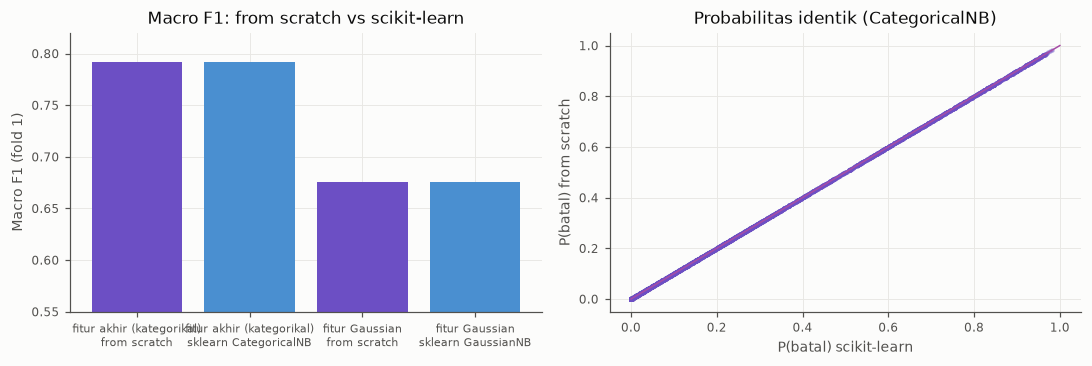

In [39]:
fit_idx, val_idx = stratified_folds(y, CFG.FOLDS, CFG.SEED)[0]
rows = []

prep = Preprocessor(final_spec())
Xf = prep.fit_transform(train.iloc[fit_idx], y[fit_idx]); Xv = prep.transform(train.iloc[val_idx])
mf, mv = ~np.isnan(Xf).any(axis=1), ~np.isnan(Xv).any(axis=1)
Xf, yf, Xv, yv = Xf[mf], y[fit_idx][mf], Xv[mv], y[val_idx][mv]
print(f'baris lengkap: latih {len(Xf)} dari {len(fit_idx)}, validasi {len(Xv)} dari {len(val_idx)}')
t0 = time.perf_counter(); ours = NaiveBayes(alpha=FINAL_ALPHA).fit(Xf, yf, prep.feature_types_); t_ours = time.perf_counter() - t0
n_cat = np.maximum(Xf.max(axis=0), Xv.max(axis=0)).astype(int) + 1
t0 = time.perf_counter(); ref = CategoricalNB(alpha=FINAL_ALPHA, min_categories=n_cat).fit(Xf.astype(int), yf); t_ref = time.perf_counter() - t0
p_ours, p_ref = ours.predict_proba(Xv), ref.predict_proba(Xv.astype(int))
rows.append({'kasus': 'fitur akhir (kategorikal)', 'model': 'from scratch',
             'macro_f1': macro_f1(yv, ours.predict(Xv, FINAL_THRESHOLD).astype(int)),
             'roc_auc': roc_auc(yv, p_ours[:, 1]), 'detik_fit': t_ours})
rows.append({'kasus': 'fitur akhir (kategorikal)', 'model': 'scikit-learn CategoricalNB',
             'macro_f1': macro_f1(yv, (p_ref[:, 1] / p_ref[:, 0] > np.exp(FINAL_THRESHOLD)).astype(int)),
             'roc_auc': roc_auc(yv, p_ref[:, 1]), 'detik_fit': t_ref})
print(f'selisih probabilitas maksimum (kategorikal): {np.abs(p_ours - p_ref).max():.2e}')

gspec = {c: 'gauss' for c in ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'weekend_nights', 'special_requests']}
gp = Preprocessor(gspec)
Gf = gp.fit_transform(train.iloc[fit_idx], y[fit_idx]); Gv = gp.transform(train.iloc[val_idx])
gf, gv = ~np.isnan(Gf).any(axis=1), ~np.isnan(Gv).any(axis=1)
Gf, gyf, Gv, gyv = Gf[gf], y[fit_idx][gf], Gv[gv], y[val_idx][gv]
t0 = time.perf_counter(); g_ours = NaiveBayes().fit(Gf, gyf, gp.feature_types_); t_ours = time.perf_counter() - t0
t0 = time.perf_counter(); g_ref = GaussianNB().fit(Gf, gyf); t_ref = time.perf_counter() - t0
gp_ours, gp_ref = g_ours.predict_proba(Gv), g_ref.predict_proba(Gv)
rows.append({'kasus': 'fitur Gaussian', 'model': 'from scratch', 'macro_f1': macro_f1(gyv, g_ours.predict(Gv).astype(int)),
             'roc_auc': roc_auc(gyv, gp_ours[:, 1]), 'detik_fit': t_ours})
rows.append({'kasus': 'fitur Gaussian', 'model': 'scikit-learn GaussianNB', 'macro_f1': macro_f1(gyv, g_ref.predict(Gv).astype(int)),
             'roc_auc': roc_auc(gyv, gp_ref[:, 1]), 'detik_fit': t_ref})
print(f'selisih probabilitas maksimum (Gaussian): {np.abs(gp_ours - gp_ref).max():.2e}')
compare = pd.DataFrame(rows).round(5)
display(compare)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
labels_ = [f"{r['kasus']}\n{r['model'].replace('scikit-learn ', 'sklearn ')}" for r in rows]
axes[0].bar(range(4), compare.macro_f1, color=[CFG.POS_COLOR, CFG.NEG_COLOR, CFG.POS_COLOR, CFG.NEG_COLOR])
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(labels_, fontsize=7)
axes[0].set_ylim(0.55, 0.82); axes[0].set_ylabel('Macro F1 (fold 1)'); axes[0].set_title('Macro F1: from scratch vs scikit-learn')
axes[1].scatter(p_ref[:, 1], p_ours[:, 1], s=4, alpha=0.4, color=CFG.POS_COLOR)
axes[1].plot([0, 1], [0, 1], color=CFG.ACCENT_COLOR, lw=1)
axes[1].set_xlabel('P(batal) scikit-learn'); axes[1].set_ylabel('P(batal) from scratch'); axes[1].set_title('Probabilitas identik (CategoricalNB)')
save_fig('nb_vs_sklearn')

#### Insights

> Implementasi from scratch menghasilkan probabilitas yang identik dengan scikit-learn: selisih maksimum 3,8e-15 untuk `CategoricalNB` dan 8,7e-15 untuk `GaussianNB`. Macro F1 dan ROC-AUC pada fold pertama sama persis (0,79164 dan 0,86738 untuk fitur akhir, 0,67554 dan 0,74738 untuk blok Gaussian). Ini membuktikan ketepatan implementasi, bukan keunggulan akurasi, karena keduanya model yang sama. Perbandingan hanya memakai baris yang lengkap (16.287 dari 21.847 baris latih, 4.138 dari 5.462 baris validasi) karena scikit-learn tidak menerima nilai kosong, sehingga angkanya lebih tinggi daripada validasi silang penuh dan tidak boleh dibandingkan langsung dengannya. Waktu fit sama-sama di bawah 0,03 detik, dan perbedaan dari satu kali pengukuran tidak bermakna.

---

# Saving and Loading Models <a name="9"></a>

---

Model akhir tidak cukup disimpan sebagai tabel peluang saja. Sebuah *artifact* menyimpan **preprocessor yang sudah dilatih** (titik potong MDL, daftar kategori, batas pemangkasan) bersama **model yang sudah dilatih**, ditambah metadata: alpha, threshold, daftar fitur, skor validasi silang, serta versi Python dan NumPy. Dengan artifact, prediksi tidak butuh data latih: cukup `load_artifact` lalu `predict_labels`. Formatnya JSON, bukan pickle, supaya aman dimuat dan bisa dibaca manusia.

Sel pertama mendefinisikan fungsi simpan dan muat. Sel kedua melatih kedua model pada seluruh `train`, menyimpannya, memuatnya tanpa `fit`, lalu memeriksa bahwa hasilnya identik dengan model yang dilatih ulang.

In [40]:
ARTIFACT_VERSION = 1

def artifact_path(model_name):
    return CFG.OUTPUT_DIR / f'{model_name}_artifact.json'

def save_artifact(model_name, prep, model, meta):
    meta = {'format_version': ARTIFACT_VERSION, 'model': model_name,
            'alpha': MODELS[model_name]['alpha'], 'threshold': MODELS[model_name]['threshold'],
            'features': FINAL_FEATURES, 'created_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
            'python_version': platform.python_version(), 'numpy_version': np.__version__, **meta}
    CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    path = artifact_path(model_name)
    with open(path, 'w', encoding='utf-8') as file:
        json.dump({'meta': meta, 'preprocessor': prep.to_dict(), 'model': model.to_dict()}, file)
    return path

def load_artifact(model_name):
    with open(artifact_path(model_name), encoding='utf-8') as file:
        payload = json.load(file)
    if payload['meta']['format_version'] != ARTIFACT_VERSION:
        raise ValueError(f"artifact format {payload['meta']['format_version']} != {ARTIFACT_VERSION}")
    prep = Preprocessor.from_dict(payload['preprocessor'])
    model = MODELS[model_name]['cls'].from_dict(payload['model'])
    return prep, model, payload['meta']

def train_and_save(model_name):
    config = MODELS[model_name]
    cv = cross_validate(final_spec(), config['cls'], train, y, seed=CFG.SEED, thresholds=THRESHOLD_GRID,
                        model_kwargs={'alpha': config['alpha']})
    prep, model = fit_pipeline(model_name, train)
    return save_artifact(model_name, prep, model, {
        'seed': CFG.SEED, 'n_train_rows': len(train), 'cv_macro_f1': cv['macro_f1_held_out_threshold'],
        'cv_roc_auc': cv['roc_auc'], 'cv_best_threshold': cv['best_threshold']})

def predict_labels(model_name, df, threshold=None):
    prep, model, meta = load_artifact(model_name)
    threshold = meta['threshold'] if threshold is None else threshold
    return model.predict(prep.transform(df), threshold=threshold).astype(int)

In [41]:
rows = []
for name in MODELS:
    path = train_and_save(name)
    prep, model, meta = load_artifact(name)
    fresh_prep, fresh_model = fit_pipeline(name, train)
    X_loaded, X_fresh = prep.transform(test), fresh_prep.transform(test)
    rows.append({'model': name, 'ukuran artifact (KB)': round(path.stat().st_size / 1024, 1),
                 'preprocessor termuat identik': bool(np.array_equal(X_loaded, X_fresh, equal_nan=True)),
                 'probabilitas model termuat identik': bool(np.array_equal(model.predict_proba(X_loaded),
                                                                           fresh_model.predict_proba(X_fresh)))})
display(pd.DataFrame(rows))
prep, model, meta = load_artifact('nb')
keys = ('format_version', 'model', 'alpha', 'threshold', 'n_train_rows', 'cv_macro_f1', 'cv_roc_auc',
        'created_at', 'python_version', 'numpy_version')
display(pd.Series({k: meta[k] for k in keys}).to_frame('nilai (artifact nb)'))

,model,ukuran artifact (KB),preprocessor termuat identik,probabilitas model termuat identik
0,nb,10.9,True,True
1,tan,226.8,True,True


,nilai (artifact nb)
format_version,1
model,nb
alpha,1.0
threshold,-0.2
n_train_rows,27309
cv_macro_f1,0.7815
cv_roc_auc,0.8636
created_at,2026-11-23T06:14:28+00:00
python_version,3.13.3
numpy_version,2.5.4


#### Insights

> Artifact Naive Bayes berukuran 10,9 KB. Preprocessor dan probabilitas model yang dimuat dari berkas identik dengan hasil pelatihan ulang (`np.array_equal`, bukan sekadar mendekati), karena JSON menyimpan angka desimal tanpa kehilangan presisi. Metadata ikut tersimpan (alpha 1,0, threshold -0,2, 27.309 baris latih, skor validasi silang Macro F1 0,7815 dan ROC-AUC 0,8636, versi Python 3.13.3 dan NumPy 2.5.4), sehingga hasilnya bisa ditelusuri.

---

# Kaggle Submission <a name="10"></a>

---

Prediksi test dibuat **hanya dari artifact** (bagian Saving and Loading Models): berkas dimuat, test diubah dengan preprocessor yang tersimpan, lalu diprediksi. Tidak ada pelatihan di bagian ini. Seluruh statistik preprocessing hanya berasal dari train, dan train serta test tidak digabung.

In [42]:
def write_submission(model_name, cost_sensitive=False):
    threshold = COST_THRESHOLD if cost_sensitive else None
    labels = predict_labels(model_name, test, threshold)
    filename = f"submission_{model_name}{'_cost_sensitive' if cost_sensitive else ''}.csv"
    CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({ID_COL: test[ID_COL], TARGET: labels}).to_csv(CFG.OUTPUT_DIR / filename, index=False)
    print(f'{filename} canceled_share={labels.mean():.4f} rows={len(labels)}')
    return CFG.OUTPUT_DIR / filename

submission_nb.csv canceled_share=0.3082 rows=6844
submission_tan.csv canceled_share=0.3162 rows=6844
format sesuai sample_submission.csv untuk semua berkas
baris 6844, porsi batal pada train 0.3275
baris yang berbeda antara NB dan TAN: 883 dari 6844


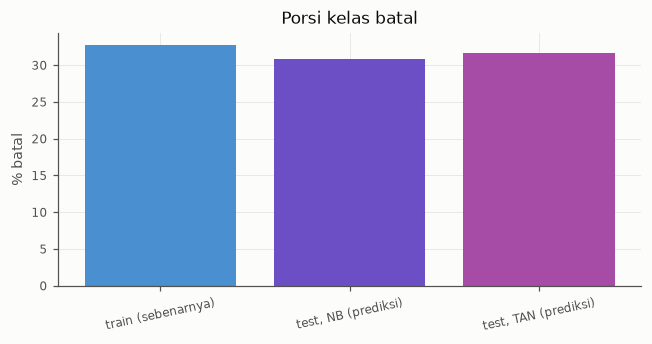

In [43]:
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
share = {'train (sebenarnya)': y.mean() * 100}
labels_by_model = {}
for name in MODELS:
    path = write_submission(name)
    sub = pd.read_csv(path)
    assert list(sample.columns) == list(sub.columns) and (sample['id'] == sub['id']).all()
    labels_by_model[name] = sub[TARGET].to_numpy()
    share[f'test, {name.upper()} (prediksi)'] = labels_by_model[name].mean() * 100
print('format sesuai sample_submission.csv untuk semua berkas')
print(f'baris {len(sample)}, porsi batal pada train {y.mean():.4f}')
print(f"baris yang berbeda antara NB dan TAN: {(labels_by_model['nb'] != labels_by_model['tan']).sum()} dari {len(sample)}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(list(share), list(share.values()), color=[CFG.NEG_COLOR, CFG.POS_COLOR, CFG.ACCENT_COLOR])
ax.set_ylabel('% batal'); ax.set_title('Porsi kelas batal'); plt.xticks(rotation=12)
save_fig('nb_submission_share')

#### Insights

> Kedua berkas berisi 6.844 baris dan formatnya sama dengan `sample_submission.csv`. Porsi yang diprediksi batal 30,82% untuk Naive Bayes dan 31,62% untuk TAN, keduanya mendekati porsi batal pada train (32,75%), tanda bahwa threshold tidak menggeser distribusi secara berlebihan. Sebanyak 883 dari 6.844 baris (12,9%) berbeda antara kedua model. Berdasarkan validasi silang dan hold-out, berkas yang sebaiknya dikirim ke Kaggle adalah `submission_tan.csv`; `submission_nb.csv` tetap menjadi baseline from scratch. Skor leaderboard Kaggle belum diperiksa dan harus dicatat setelah berkas diunggah.

Untuk bonus cost-sensitive, berkas kedua ditulis untuk Naive Bayes dengan threshold $\log 2$ (analisis Cost-Sensitive Classification dilakukan pada Naive Bayes). Berkas ini bukan pengganti submisi di atas: ia menurunkan biaya, tetapi menurunkan Macro F1, metrik yang dinilai di Kaggle.

In [44]:
path_cost = write_submission('nb', cost_sensitive=True)
labels_nb = labels_by_model['nb']
submission_cost = pd.read_csv(path_cost)
labels_cost = submission_cost[TARGET].to_numpy()
assert list(sample.columns) == list(submission_cost.columns) and (sample['id'] == submission_cost['id']).all()
print(f'porsi diprediksi batal: {labels_cost.mean():.4f} (submission_nb.csv: {labels_nb.mean():.4f})')
print(f'baris yang berbeda dari submission_nb.csv: {(labels_cost != labels_nb).sum()} dari {len(labels_nb)}')
print('arah perbedaan (NB minus cost-sensitive):', pd.Series(labels_nb - labels_cost).value_counts().to_dict())

submission_nb_cost_sensitive.csv canceled_share=0.1918 rows=6844
porsi diprediksi batal: 0.1918 (submission_nb.csv: 0.3082)
baris yang berbeda dari submission_nb.csv: 796 dari 6844
arah perbedaan (NB minus cost-sensitive): {0: 6048, 1: 796}


#### Insights

> Berkas cost-sensitive memprediksi 19,18% baris batal, dibanding 30,82% pada `submission_nb.csv`. Sebanyak 796 dari 6.844 baris berbeda, semuanya berubah dari batal menjadi tidak batal, sebagaimana diharapkan karena threshold yang lebih tinggi hanya membuang prediksi batal. Berkas ini hanya dibuat untuk Naive Bayes karena analisis Cost-Sensitive Classification dilakukan pada Naive Bayes; kalibrasi probabilitas TAN belum diperiksa sehingga threshold $\log 2$ belum dipakai padanya. Berkas ini tidak dimaksudkan untuk leaderboard karena menurunkan Macro F1 (pada hold-out dari 0,776 menjadi 0,728).

---

# Error Analysis <a name="11"></a>

---

Analisis ini dipakai untuk menjelaskan di mana model salah dan mengapa. Prediksi yang dipakai adalah prediksi *out-of-fold* dari Stratified 5-Fold (seed 42) atas seluruh `train`, sehingga setiap baris dinilai oleh model yang tidak pernah melihatnya. Naive Bayes dan TAN memakai fitur akhir dan threshold masing-masing dari `MODELS`.

### Confusion Matrix dan Jenis Kesalahan

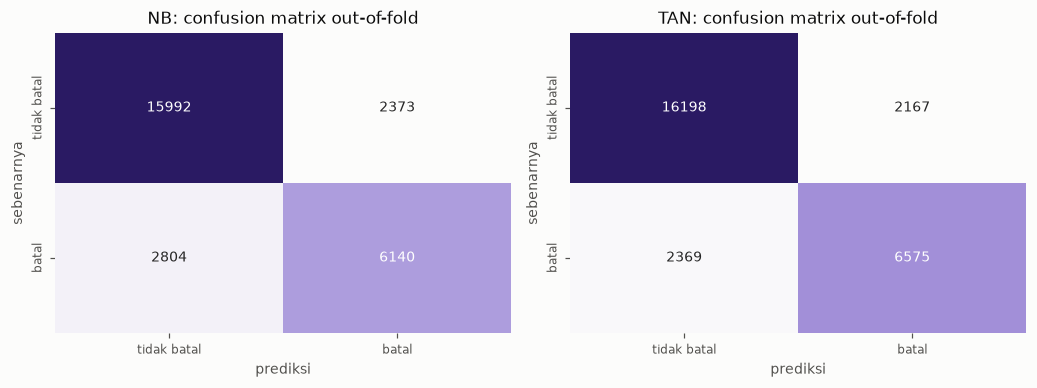

,model,FP,FN,error rate,presisi batal,recall batal,macro_f1
0,NB,2373,2804,0.1896,0.7212,0.6865,0.7821
1,TAN,2167,2369,0.1661,0.7521,0.7351,0.8104


In [45]:
oof, pred = {}, {}
for name, cfg in MODELS.items():
    r = cross_validate(final_spec(), cfg['cls'], train, y, n_folds=CFG.FOLDS, seed=CFG.SEED,
                       model_kwargs={'alpha': cfg['alpha']})
    oof[name] = r['odds']
    pred[name] = (r['odds'] > cfg['threshold']).astype(int)

rows = []
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(y, pred[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap=SEQUENTIAL, cbar=False, ax=ax,
                xticklabels=['tidak batal', 'batal'], yticklabels=['tidak batal', 'batal'])
    ax.set_xlabel('prediksi'); ax.set_ylabel('sebenarnya'); ax.grid(False)
    ax.set_title(f'{name.upper()}: confusion matrix out-of-fold')
    tn, fp, fn, tp = cm.ravel()
    rows.append({'model': name.upper(), 'FP': fp, 'FN': fn, 'error rate': (fp + fn) / len(y),
                 'presisi batal': tp / (tp + fp), 'recall batal': tp / (tp + fn),
                 'macro_f1': macro_f1(y, pred[name])})
save_fig('nb_error_confusion')
display(pd.DataFrame(rows).round(4))

#### Insights

> TAN mengurangi kedua jenis kesalahan dibanding Naive Bayes: FP turun dari 2.373 menjadi 2.167 dan FN dari 2.804 menjadi 2.369, sehingga error rate turun dari 18,96% menjadi 16,61%. Presisi kelas batal naik dari 0,721 menjadi 0,752 dan recall dari 0,687 menjadi 0,735 (Macro F1 0,7821 menjadi 0,8104).

> Pada kedua model FN lebih banyak daripada FP, artinya model lebih sering melewatkan pembatalan daripada menuduh tamu batal padahal datang. Pola ini sejalan dengan kelas batal yang hanya 32,75% dari data.

### Kesalahan per Segmen Data

error rate keseluruhan: NB 18.96%, TAN 16.61%
segmen dengan error TAN tertinggi:


,atribut,nilai,baris,% batal,error NB %,error TAN %,FP TAN %,FN TAN %
0,lead_time,kosong,1120,31.25,26.52,26.07,8.48,17.59
1,meal_package,Room Only,3713,33.80,22.14,21.84,8.89,12.95
2,special_requests,kosong,2499,40.86,26.93,21.65,6.12,15.53
3,lead_time,"(99.0, 167.0]",4308,42.66,25.81,21.54,11.42,10.12
4,lead_time,"(58.0, 99.0]",4322,29.59,22.30,21.03,9.90,11.13
5,booking_channel,Online Travel Agent,17507,36.37,20.62,20.24,9.41,10.83
6,room_category,Type G,4396,34.19,21.20,20.13,9.55,10.58
7,room_category,Type A,699,42.63,19.60,19.60,9.59,10.01


segmen dengan error TAN terendah:


,atribut,nilai,baris,% batal,error NB %,error TAN %,FP TAN %,FN TAN %
0,special_requests,3.0,496,0.00,0.00,2.62,2.62,0.00
1,booking_channel,Complimentary,300,0.00,0.00,4.33,4.33,0.00
2,special_requests,2.0,3246,14.29,8.90,9.58,4.47,5.11
3,lead_time,"(-0.001, 8.0]",4401,10.09,10.61,10.04,3.29,6.75
4,booking_channel,Offline Agent,7902,30.06,17.53,10.11,5.69,4.42


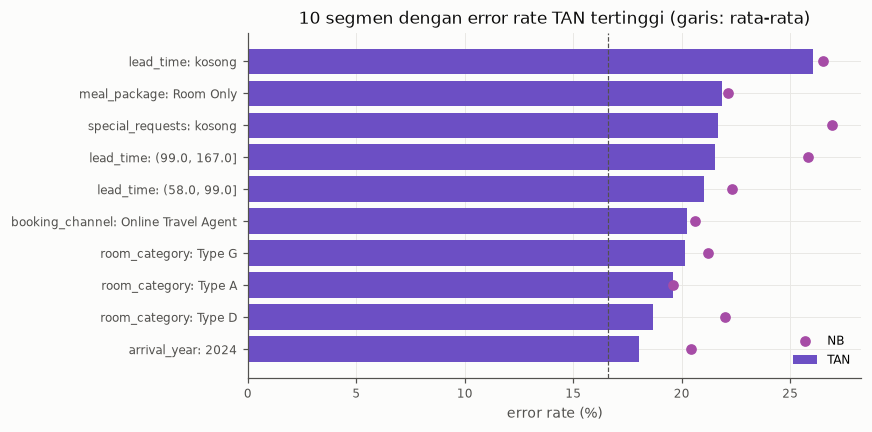

In [46]:
wrong = {n: pred[n] != y for n in pred}
fp_tan = (pred['tan'] == 1) & (y == 0)
fn_tan = (pred['tan'] == 0) & (y == 1)

frame = train[['booking_channel', 'special_requests', 'room_category', 'meal_package',
               'arrival_year', 'prior_completed_bookings']].copy()
frame.insert(0, 'lead_time', pd.qcut(train.days_before_arrival, 6, duplicates='drop').astype(str))
rows = []
for dim in frame.columns:
    key = frame[dim].astype(object).where(frame[dim].notna(), 'kosong').astype(str)
    for value in key.unique():
        m = (key == value).to_numpy()
        if m.sum() < 200:
            continue
        rows.append({'atribut': dim, 'nilai': value, 'baris': int(m.sum()), '% batal': y[m].mean() * 100,
                     'error NB %': wrong['nb'][m].mean() * 100, 'error TAN %': wrong['tan'][m].mean() * 100,
                     'FP TAN %': fp_tan[m].mean() * 100, 'FN TAN %': fn_tan[m].mean() * 100})
segments = pd.DataFrame(rows)
overall = {n: wrong[n].mean() * 100 for n in wrong}
print(f"error rate keseluruhan: NB {overall['nb']:.2f}%, TAN {overall['tan']:.2f}%")
print('segmen dengan error TAN tertinggi:')
display(segments.sort_values('error TAN %', ascending=False).head(8).round(2).reset_index(drop=True))
print('segmen dengan error TAN terendah:')
display(segments.sort_values('error TAN %').head(5).round(2).reset_index(drop=True))

top = segments.sort_values('error TAN %', ascending=False).head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
labels_seg = [f"{a}: {v}" for a, v in zip(top['atribut'], top['nilai'])]
ax.barh(labels_seg, top['error TAN %'], color=CFG.POS_COLOR, label='TAN')
ax.scatter(top['error NB %'], labels_seg, color=CFG.ACCENT_COLOR, zorder=3, label='NB')
ax.axvline(overall['tan'], color=CFG.MUTED, lw=0.8, ls='--')
ax.set_xlabel('error rate (%)'); ax.set_title('10 segmen dengan error rate TAN tertinggi (garis: rata-rata)'); ax.legend()
save_fig('nb_error_segments')

#### Insights

> Kesalahan terkonsentrasi pada baris yang informasinya hilang atau tidak tegas. Error TAN tertinggi ada pada baris dengan `days_before_arrival` kosong (26,07%, FN 17,59% dibanding FP 8,48%) dan `special_requests` kosong (21,65%, FN 15,53%). Keduanya adalah komponen fitur gabungan yang dipilih forward selection di langkah pertama dan kedua (`x_lead5_period` dan `x_sr_channel`), sehingga saat nilainya kosong model kehilangan sinyal terkuatnya dan lebih sering menebak tidak batal.

> Lead time menengah juga sulit: kelompok 58 sampai 99 hari (error TAN 21,03%, batal 29,6%) dan 99 sampai 167 hari (21,54%, batal 42,7%) berada dekat batas keputusan. Segmen paling mudah adalah `special_requests` 3 (error 2,62%, tidak ada yang batal), kanal Complimentary (4,33%, tidak ada yang batal), dan lead time sangat pendek, 8 hari atau kurang (10,04%, batal 10,1%).

> TAN paling banyak memperbaiki kanal Offline Agent (error NB 17,53% menjadi 10,11%) dan baris dengan `special_requests` kosong (26,93% menjadi 21,65%), dua segmen tempat fitur saling bergantung paling terasa.

### Keyakinan Model dan Kesalahan

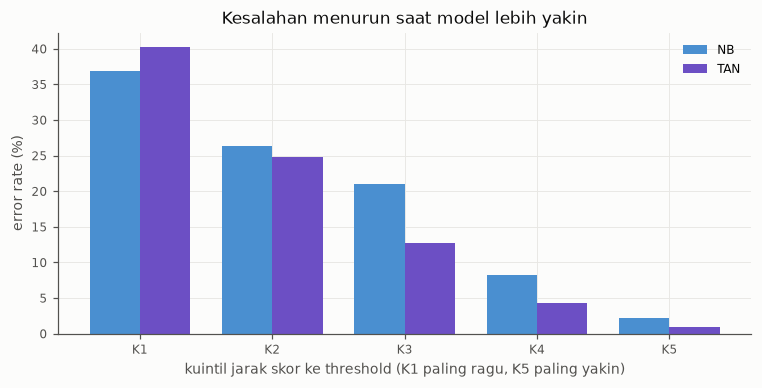

,model,kuintil keyakinan,jarak ke threshold (rata-rata),error rate %
0,NB,1,0.313,36.921
1,NB,2,0.831,26.409
2,NB,3,1.355,21.015
3,NB,4,2.134,8.239
4,NB,5,4.869,2.197
5,TAN,1,0.436,40.223
6,TAN,2,1.333,24.844
7,TAN,3,2.448,12.761
8,TAN,4,4.009,4.339
9,TAN,5,6.914,0.879


In [47]:
rows = []
fig, ax = plt.subplots(figsize=(7, 3.6))
width = 0.38
for k, (name, color) in enumerate((('nb', CFG.NEG_COLOR), ('tan', CFG.POS_COLOR))):
    margin = np.abs(oof[name] - MODELS[name]['threshold'])
    quintile = pd.qcut(margin, 5, labels=False)
    rate = [wrong[name][quintile == q].mean() * 100 for q in range(5)]
    ax.bar(np.arange(5) + (k - 0.5) * width, rate, width, color=color, label=name.upper())
    for q in range(5):
        rows.append({'model': name.upper(), 'kuintil keyakinan': q + 1,
                     'jarak ke threshold (rata-rata)': margin[quintile == q].mean(), 'error rate %': rate[q]})
ax.set_xticks(range(5)); ax.set_xticklabels([f'K{q + 1}' for q in range(5)])
ax.set_xlabel('kuintil jarak skor ke threshold (K1 paling ragu, K5 paling yakin)'); ax.set_ylabel('error rate (%)')
ax.set_title('Kesalahan menurun saat model lebih yakin'); ax.legend()
save_fig('nb_error_confidence')
display(pd.DataFrame(rows).round(3))

#### Insights

> Kesalahan turun tajam ketika model yakin. Pada kuintil paling yakin (K5), error Naive Bayes 2,20% dan TAN 0,88%, sedangkan pada kuintil paling ragu (K1) 36,92% dan 40,22%, mendekati tebakan acak. Kuintil dihitung per model, sehingga jarak ke threshold tidak sebanding antar model: skor TAN lebih tegas (rata-rata jarak pada K5 6,91 dibanding 4,87), tetapi pada baris yang paling ragu TAN tidak lebih baik daripada Naive Bayes.

> Artinya skor log odds informatif, dan baris dengan jarak kecil ke threshold layak ditandai untuk ditinjau manual bila hotel ingin mengurangi keputusan yang salah.

### Nilai Kosong, Perbedaan NB dan TAN

In [48]:
n_skipped = np.isnan(X_final).sum(axis=1)
group = np.minimum(n_skipped, 3)
rows = []
for g in range(4):
    m = group == g
    rows.append({'fitur dilewati': f'{g}' if g < 3 else '3 atau lebih', 'baris': int(m.sum()),
                 '% batal': y[m].mean() * 100, 'error NB %': wrong['nb'][m].mean() * 100,
                 'error TAN %': wrong['tan'][m].mean() * 100})
display(pd.DataFrame(rows).round(2))

differ = pred['nb'] != pred['tan']
print(f'baris yang diprediksi berbeda oleh NB dan TAN: {differ.sum()} ({differ.mean() * 100:.1f}%)')
print(f"pada baris itu TAN benar {(pred['tan'] == y)[differ].mean() * 100:.1f}%, NB benar {(pred['nb'] == y)[differ].mean() * 100:.1f}%")
print(f"kedua model salah bersamaan: {(wrong['nb'] & wrong['tan']).sum()} baris "
      f"({(wrong['nb'] & wrong['tan']).sum() / wrong['tan'].sum() * 100:.1f}% dari kesalahan TAN)")

,fitur dilewati,baris,% batal,error NB %,error TAN %
0,0,20425,32.19,17.95,15.93
1,1,6108,33.97,21.33,18.30
2,2,743,38.22,27.05,21.40
3,3 atau lebih,33,30.30,21.21,15.15


baris yang diprediksi berbeda oleh NB dan TAN: 3831 (14.0%)
pada baris itu TAN benar 58.4%, NB benar 41.6%
kedua model salah bersamaan: 2941 baris (64.8% dari kesalahan TAN)


#### Insights

> Semakin banyak fitur yang dilewati karena nilainya kosong, semakin tinggi error. Pada TAN error naik dari 15,93% (tidak ada fitur dilewati) menjadi 18,30% (satu) dan 21,40% (dua), sedangkan Naive Bayes dari 17,95% menjadi 21,33% dan 27,05%. Kenaikan TAN dari nol ke dua fitur (5,5 poin) lebih kecil daripada Naive Bayes (9,1 poin). Kelompok tiga fitur atau lebih hanya 33 baris sehingga tidak ditafsirkan.

> Kedua model berbeda prediksi pada 3.831 baris (14,0%), dan pada baris itu TAN benar 58,4% sedangkan Naive Bayes 41,6%. Sebanyak 2.941 baris, atau 64,8% dari kesalahan TAN, juga salah pada Naive Bayes. Jadi sebagian besar kesalahan kemungkinan berasal dari batas informasi pada fitur yang ada, bukan hanya dari asumsi independensi yang dilonggarkan TAN.